In [1]:
%env OPENBLAS_NUM_THREADS=1
%env MKL_NUM_THREADS=1
%env NUMEXPR_NUM_THREADS=1

import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"   # macOS Accelerate
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["BLIS_NUM_THREADS"] = "1"
os.environ["OMP_DYNAMIC"] = "FALSE"

env: OPENBLAS_NUM_THREADS=1
env: MKL_NUM_THREADS=1
env: NUMEXPR_NUM_THREADS=1


In [2]:
from utils import load_counties, load_cbsa

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import geopandas as gpd
from shapely.geometry import Point
from shapely import wkt

import re

import networkx as nx
from scipy import integrate
from scipy.stats import norm

import glob
from tqdm import tqdm

In [3]:
from pathlib import Path

output_dir = Path("../data_generated/network_metrics")
output_dir.mkdir(parents=True, exist_ok=True)

In [4]:
# from https://github.com/shuaib7860/weighted_hits/blob/main/weighted_hits.py

def weighted_hits(G, weight='weight', max_iter=100, tol=1.0e-8, nstart=None, normalized=True):
    """Returns HITS hubs and authorities values for nodes.

    The HITS algorithm computes two numbers for a node.
    Authorities estimates the node value based on the incoming links.
    Hubs estimates the node value based on outgoing links.

    Parameters
    ----------
    G : graph
      A NetworkX graph

    max_iter : integer, optional
      Maximum number of iterations in power method.

    tol : float, optional
      Error tolerance used to check convergence in power method iteration.

    nstart : dictionary, optional
      Starting value of each node for power method iteration.

    normalized : bool (default=True)
       Normalize results by the sum of all of the values.

    Returns
    -------
    (hubs,authorities) : two-tuple of dictionaries
       Two dictionaries keyed by node containing the hub and authority
       values.

    Raises
    ------
    PowerIterationFailedConvergence
        If the algorithm fails to converge to the specified tolerance
        within the specified number of iterations of the power iteration
        method.

    Examples
    --------
    >>> G = nx.path_graph(4)
    >>> h, a = nx.hits(G)

    Notes
    -----
    The eigenvector calculation is done by the power iteration method
    and has no guarantee of convergence.  The iteration will stop
    after max_iter iterations or an error tolerance of
    number_of_nodes(G)*tol has been reached.

    The HITS algorithm was designed for directed graphs but this
    algorithm does not check if the input graph is directed and will
    execute on undirected graphs.

    References
    ----------
    .. [1] A. Langville and C. Meyer,
       "A survey of eigenvector methods of web information retrieval."
       http://citeseer.ist.psu.edu/713792.html
    .. [2] Jon Kleinberg,
       Authoritative sources in a hyperlinked environment
       Journal of the ACM 46 (5): 604-32, 1999.
       doi:10.1145/324133.324140.
       http://www.cs.cornell.edu/home/kleinber/auth.pdf.
    """
    if type(G) == nx.MultiGraph or type(G) == nx.MultiDiGraph:
        raise Exception("hits() not defined for graphs with multiedges.")
    if len(G) == 0:
        return {}, {}
    # choose fixed starting vector if not given
    if nstart is None:
        h = dict.fromkeys(G, 1.0 / G.number_of_nodes())
    else:
        h = nstart
        # normalize starting vector
        s = 1.0 / sum(h.values())
        for k in h:
            h[k] *= s
    for _ in range(max_iter):  # power iteration: make up to max_iter iterations
        hlast = h
        h = dict.fromkeys(hlast.keys(), 0)
        a = dict.fromkeys(hlast.keys(), 0)
        # this "matrix multiply" looks odd because it is
        # doing a left multiply a^T=hlast^T*G
        for n in h:
            for nbr in G[n]:
                a[nbr] += hlast[n] * G[n][nbr][weight]
        # now multiply h=Ga
        for n in h:
            for nbr in G[n]:
                h[n] += a[nbr] * G[n][nbr][weight]
        # normalize vector
        s = 1.0 / max(h.values())
        for n in h:
            h[n] *= s
        # normalize vector
        s = 1.0 / max(a.values())
        for n in a:
            a[n] *= s
        # check convergence, l1 norm
        err = sum([abs(h[n] - hlast[n]) for n in h])
        if err < tol:
            break
    else:
        raise nx.PowerIterationFailedConvergence(max_iter)
    if normalized:
        s = 1.0 / sum(a.values())
        for n in a:
            a[n] *= s
        s = 1.0 / sum(h.values())
        for n in h:
            h[n] *= s
    return h, a

In [5]:
df = pd.read_parquet("../data_generated/experience.parquet")

y1 = "2011-01-01"
y2 = "2022-12-31"

df_win = (
    df[(df['next_start_date'] >= y1) &
       (df['next_start_date'] <=  y2) &
       (df['next_job_zone'] >= 4.0)]
    .replace("nannan", np.nan) # for STCOFIPS and STCOFIPS_next
    .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
    .assign(
        STCOFIPS = lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
        STCOFIPS_next = lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
    )
)

# remove self-loops here
df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

print(df_win.PERSON_ID.nunique())

df_win.to_parquet("../data_generated/df_win.parquet")

128006


/tmp/ipykernel_4427/1940531172.py:169: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax4.set_xticklabels(ax4.get_xticklabels(), rotation=90)


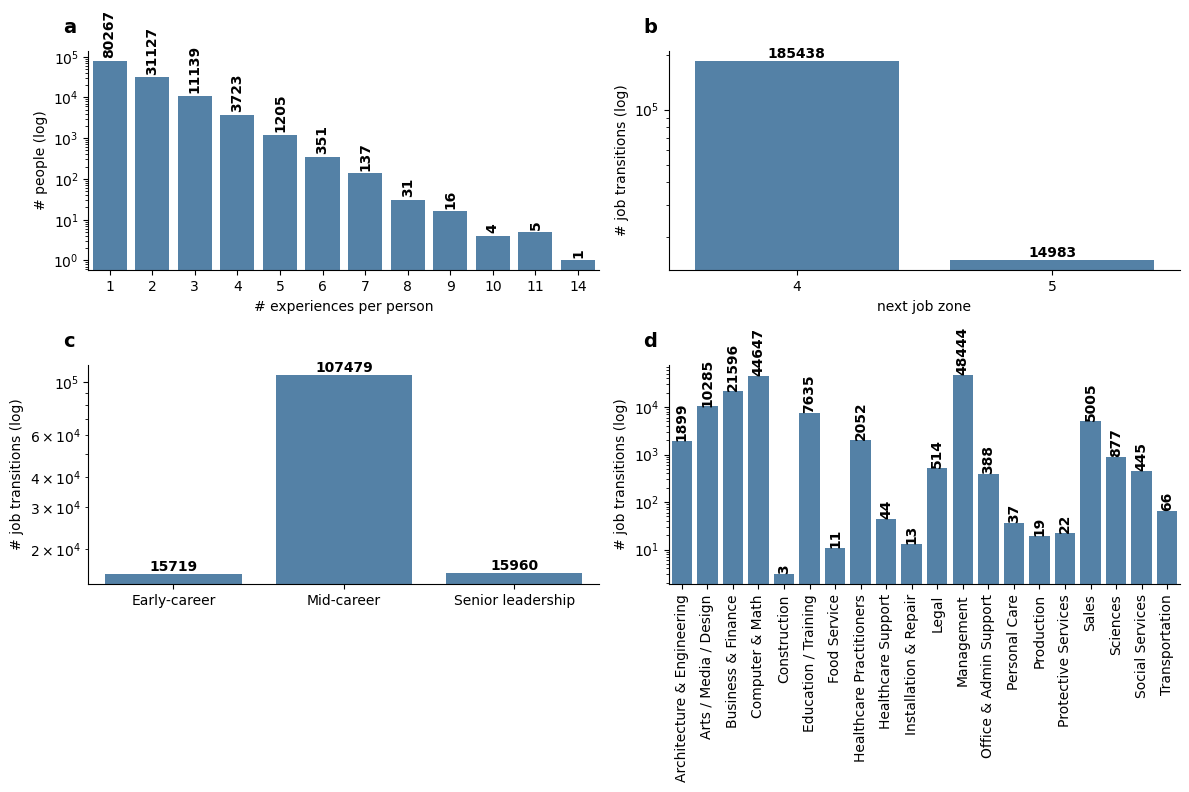

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
(ax1, ax2), (ax3, ax4) = axes

# ============================================================
# 1. Experiences per person
# ============================================================

exp_counts = (
    df_win.groupby('PERSON_ID')['EXPERIENCE_ID']
    .count()
    .reset_index()
    .EXPERIENCE_ID
    .value_counts()
    .sort_index()
    .reset_index()
)
exp_counts.columns = ['n_experiences', 'n_people']

sns.barplot(
    data=exp_counts,
    x='n_experiences',
    y='n_people',
    color='steelblue',
    ax=ax1
)

# labels
for i, row in exp_counts.iterrows():
    if row['n_experiences'] >= 0:
        ax1.text(
            x=i,
            y=row['n_people'] * 1.15,
            s=f"{int(row['n_people'])}",
            ha='center',
            va='bottom',
            fontweight='bold',
            rotation=90
        
        )

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.set_yscale("log")
ax1.set_xlabel("# experiences per person")
ax1.set_ylabel("# people (log)")


# ============================================================
# 2. Next job zone
# ============================================================

zone_counts_z = (
    df_win['next_job_zone']
    .value_counts()
    .reset_index()
    .rename(columns={'count': 'n_people', 'next_job_zone': 'next_job_zone'})
)

zone_counts_z['next_job_zone'] = zone_counts_z['next_job_zone'].astype(int)
zone_counts_z = zone_counts_z.sort_values('next_job_zone').reset_index(drop=True)

sns.barplot(
    data=zone_counts_z,
    x='next_job_zone',
    y='n_people',
    color='steelblue',
    ax=ax2
)

for i, row in zone_counts_z.iterrows():
    ax2.text(
        x=i,
        y=row['n_people'],
        s=f"{int(row['n_people'])}",
        ha='center',
        va='bottom',
        fontweight='bold'
    )

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.set_yscale("log")
ax2.set_xlabel("next job zone")
ax2.set_ylabel("# job transitions (log)")


# ============================================================
# 3. Next seniority group
# ============================================================

order = ["Early-career", "Mid-career", "Senior leadership"]

zone_counts_s = (
    df_win['next_seniority_group']
    .value_counts()
    .reset_index()
    .rename(columns={'count': 'n_people', 'next_seniority_group': 'next_seniority_group'})
)

zone_counts_s['next_seniority_group'] = pd.Categorical(
    zone_counts_s['next_seniority_group'],
    categories=order,
    ordered=True
)
zone_counts_s = zone_counts_s.sort_values('next_seniority_group').reset_index(drop=True)

sns.barplot(
    data=zone_counts_s,
    x='next_seniority_group',
    y='n_people',
    color='steelblue',
    ax=ax3
)

for i, row in zone_counts_s.iterrows():
    ax3.text(
        x=i,
        y=row['n_people'],
        s=f"{int(row['n_people'])}",
        ha='center',
        va='bottom',
        fontweight='bold'
    )

ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)
ax3.set_yscale("log")
ax3.set_xlabel("")
ax3.set_ylabel("# job transitions (log)")


# ============================================================
# 4. Next SOC broad category
# ============================================================

zone_counts_i = (
    df_win['next_soc_broad']
    .value_counts()
    .reset_index()
    .rename(columns={'count': 'n_people', 'next_soc_broad': 'next_soc_broad'})
)

zone_counts_i = zone_counts_i.sort_values('next_soc_broad').reset_index(drop=True)

sns.barplot(
    data=zone_counts_i,
    x='next_soc_broad',
    y='n_people',
    color='steelblue',
    ax=ax4
)

for i, row in zone_counts_i.iterrows():
    ax4.text(
        x=i,
        y=row['n_people'],
        s=f"{int(row['n_people'])}",
        ha='center',
        va='bottom',
        fontweight='bold',
        rotation=90
    )

ax4.spines["top"].set_visible(False)
ax4.spines["right"].set_visible(False)
ax4.set_yscale("log")
ax4.set_xlabel("")
ax4.set_ylabel("# job transitions (log)")
ax4.set_xticklabels(ax4.get_xticklabels(), rotation=90)

# ============================================================

plots_l = ['a', 'b', 'c', 'd']
for ia, ax in enumerate(fig.axes): 
    x,y = -0.05,1.06
    ax.text(x,y,  plots_l[ia],
        color = 'k',#'lightgreen',
        horizontalalignment='left',
        verticalalignment='bottom',
        weight = 'bold',
        transform=ax.transAxes,fontsize = 14)
    
plt.tight_layout()

plt.savefig('../fig/si/si_panel2.pdf', bbox_inches='tight')

plt.show()


## County-level Networks (2011-2022)

In [7]:
### Load IRS Migration Data

def make_fips(s,c):
    return s.astype(str).str.zfill(2) + c.astype(str).str.zfill(3)

hits_store = []
flow_store = []

for inflow_path in glob.glob("../data_loaded/irs/countyinflow*.csv"):

    label = inflow_path.split("countyinflow")[-1].split(".")[0]
    outflow_path = inflow_path.replace("countyinflow","countyoutflow")

    inflow = pd.read_csv(inflow_path, encoding="latin-1")
    outflow = pd.read_csv(outflow_path, encoding="latin-1")

    # person flows only
    inflow = inflow.rename(columns={"n2":"in_n_persons"})
    outflow = outflow.rename(columns={"n2":"out_n_persons"})

    inflow["STCOFIPS"]      = make_fips(inflow["y2_statefips"], inflow["y2_countyfips"])
    inflow["STCOFIPS_next"] = make_fips(inflow["y1_statefips"], inflow["y1_countyfips"])

    # drop records without real pairs
    df_pairs = inflow.dropna(subset=["STCOFIPS","STCOFIPS_next"])
    # remove self-loops
    df_pairs = df_pairs[df_pairs["STCOFIPS"] != df_pairs["STCOFIPS_next"]]

    # aggregate counts
    df_agg = (
        df_pairs.groupby(["STCOFIPS","STCOFIPS_next"])["in_n_persons"]
        .sum().reset_index()
    )

    df_agg=df_agg.replace(-1, np.nan).dropna()
    df_agg["window"] = f"{label}"

    flow_store.append(df_agg)

flows_irs = pd.concat(flow_store, ignore_index=True)

# removing states etc - https://www.irs.gov/pub/irs-soi/2021inpublicmigdoc.pdf 
flows_irs_clean = flows_irs[
    ~(flows_irs["STCOFIPS"].str.endswith("000") |
      flows_irs["STCOFIPS_next"].str.endswith("000"))
]

flows_irs_clean = flows_irs_clean[
    ~(flows_irs_clean["STCOFIPS"].str.startswith(("57","58","59","96","97","98")) |
      flows_irs_clean["STCOFIPS_next"].str.startswith(("57","58","59","96","97","98"))
     )
]

In [8]:
# =============================================================================
# 1. EXPERIENCE DATASET
# =============================================================================

df = pd.read_parquet("../data_generated/experience.parquet")

# Filter final job window and high-skill
df_all = (
    df[(df['next_start_date'] >= "2011-01-01") &
       (df['next_start_date'] <= "2022-12-31") &
       (df['next_job_zone'] >= 4.0)]
    .replace("nannan", np.nan)
    .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
    .assign(
        STCOFIPS=lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
        STCOFIPS_next=lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
    )
)

# remove self-loops
df_all = df_all[df_all["STCOFIPS"] != df_all["STCOFIPS_next"]]

print("Unique persons:", df_all.PERSON_ID.nunique())

# aggregate over all years
df_agg_exp = (
    df_all.groupby(['STCOFIPS', 'STCOFIPS_next'])
          .PERSON_ID.count()
          .reset_index()
          .rename(columns={'PERSON_ID': 'n'})
)

# node set before cleaning
exp_nodes_initial = set(
    pd.concat([df_agg_exp['STCOFIPS'], df_agg_exp['STCOFIPS_next']], ignore_index=True)
)
print("EXP nodes initial:", len(exp_nodes_initial))



# =============================================================================
# 2. IRS DATA
# =============================================================================

irs_nodes_initial = set(
    pd.concat([flows_irs_clean['STCOFIPS'], flows_irs_clean['STCOFIPS_next']], ignore_index=True)
)
print("IRS nodes initial:", len(irs_nodes_initial))


# =============================================================================
# 3. CLEAN NODE SETS
# =============================================================================

common_nodes = exp_nodes_initial & irs_nodes_initial 
common_nodes = sorted(common_nodes)

df_exp_clean = df_agg_exp[
    df_agg_exp["STCOFIPS"].isin(common_nodes) &
    df_agg_exp["STCOFIPS_next"].isin(common_nodes)
]

df_irs_clean = flows_irs_clean[
    flows_irs_clean["STCOFIPS"].isin(common_nodes) &
    flows_irs_clean["STCOFIPS_next"].isin(common_nodes)
]

exp_nodes_cleaned = set(
    pd.concat([df_exp_clean['STCOFIPS'], df_exp_clean['STCOFIPS_next']], ignore_index=True)
)
irs_nodes_cleaned = set(
    pd.concat([df_irs_clean['STCOFIPS'], df_irs_clean['STCOFIPS_next']], ignore_index=True)
)

common_nodes = exp_nodes_cleaned & irs_nodes_cleaned 
common_nodes = sorted(common_nodes)

# actually common nodes now
df_exp_clean = df_agg_exp[
    df_agg_exp["STCOFIPS"].isin(common_nodes) &
    df_agg_exp["STCOFIPS_next"].isin(common_nodes)
]

df_irs_clean = flows_irs_clean[
    flows_irs_clean["STCOFIPS"].isin(common_nodes) &
    flows_irs_clean["STCOFIPS_next"].isin(common_nodes)
]

df_irs_clean = (
    df_irs_clean.groupby(['STCOFIPS', 'STCOFIPS_next'])
                .in_n_persons.sum()
                .reset_index()
                .rename(columns={'in_n_persons': 'n'})
)

print("COMMON nodes (after cleaning):", len(common_nodes))


# =============================================================================
# Once again, to ensure
# =============================================================================

df_agg_exp_final = df_exp_clean[
    df_exp_clean["STCOFIPS"].isin(common_nodes) &
    df_exp_clean["STCOFIPS_next"].isin(common_nodes)
].copy()

df_agg_irs_final = df_irs_clean[
    df_irs_clean["STCOFIPS"].isin(common_nodes) &
    df_irs_clean["STCOFIPS_next"].isin(common_nodes)
].copy()

print("EXP edges after final filtering:", len(df_agg_exp_final))
print("IRS edges after final filtering:", len(df_agg_irs_final))

# =============================================================================
# BUILD EXP NETWORK
# =============================================================================

G_exp = nx.DiGraph()
G_exp.add_weighted_edges_from(
    df_agg_exp_final[["STCOFIPS", "STCOFIPS_next", "n"]].values
)

# compute centralities
hubs_exp, auth_exp = weighted_hits(G_exp, weight="weight", normalized=True)
pr_exp = nx.pagerank(G_exp, weight='weight')

hits_exp_single = pd.DataFrame({
    "STCOFIPS": common_nodes,
    "hub":      [hubs_exp.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_exp.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_exp.get(n, np.nan) for n in common_nodes]
})

hits_exp_single["rank_hub"]  = hits_exp_single["hub"].rank(method="dense", ascending=False)
hits_exp_single["rank_auth"] = hits_exp_single["auth"].rank(method="dense", ascending=False)
hits_exp_single["rank_page"] = hits_exp_single["pagerank"].rank(method="dense", ascending=False)

print("Final EXP nodes:", len(hits_exp_single))

# =============================================================================
# BUILD IRS NETWORK
# =============================================================================

G_irs = nx.DiGraph()
G_irs.add_weighted_edges_from(
    df_agg_irs_final[["STCOFIPS", "STCOFIPS_next", "n"]].values
)

# compute centralities
hubs_irs, auth_irs = weighted_hits(G_irs, weight="weight", normalized=True)
pr_irs = nx.pagerank(G_irs, weight='weight')

hits_irs_single = pd.DataFrame({
    "STCOFIPS": common_nodes,
    "hub":      [hubs_irs.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_irs.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_irs.get(n, np.nan) for n in common_nodes]
})

hits_irs_single["rank_hub"]  = hits_irs_single["hub"].rank(method="dense", ascending=False)
hits_irs_single["rank_auth"] = hits_irs_single["auth"].rank(method="dense", ascending=False)
hits_irs_single["rank_page"] = hits_irs_single["pagerank"].rank(method="dense", ascending=False)

print("Final IRS nodes:", len(hits_irs_single))

# =============================================================================
# Print results and shapes
# =============================================================================

print("\n================== SUMMARY ==================")
print("EXP nodes initial:", len(exp_nodes_initial))
print("IRS nodes initial:", len(irs_nodes_initial))
print("EXP nodes after cleaning:", len(exp_nodes_cleaned))
print("IRS nodes after cleaning:", len(irs_nodes_cleaned))
print("COMMON FINAL nodes:", len(common_nodes))
print("EXP network final size:", hits_exp_single.shape)
print("IRS network final size:", hits_irs_single.shape)
print("=============================================\n")


Unique persons: 128006
EXP nodes initial: 2119
IRS nodes initial: 3100
COMMON nodes (after cleaning): 2109
EXP edges after final filtering: 48181
IRS edges after final filtering: 97807
Final EXP nodes: 2109
Final IRS nodes: 2109

================== SUMMARY ==================
EXP nodes initial: 2119
IRS nodes initial: 3100
EXP nodes after cleaning: 2112
IRS nodes after cleaning: 2109
COMMON FINAL nodes: 2109
EXP network final size: (2109, 7)
IRS network final size: (2109, 7)



In [9]:
# save all
hits_exp_single.to_parquet("../data_generated/network_metrics/hits_exp_1122.parquet")
df_agg_exp_final.to_parquet("../data_generated/network_metrics/flows_exp_1122.parquet")

hits_irs_single.to_parquet("../data_generated/network_metrics/hits_irs_1122.parquet")
df_agg_irs_final.to_parquet("../data_generated/network_metrics/flows_irs_1122.parquet")

In [10]:
exp_nodes_cleaned = set(
    pd.concat([df_agg_exp_final['STCOFIPS'], df_agg_exp_final['STCOFIPS_next']], ignore_index=True)
)

In [11]:
len(exp_nodes_cleaned)

2109

In [12]:
flows_irs_clean[flows_irs_clean['STCOFIPS'].isin(common_nodes)&flows_irs_clean['STCOFIPS_next'].isin(common_nodes)].in_n_persons.sum()

115628071.0

In [13]:
flows_irs_clean[
    (~flows_irs_clean['STCOFIPS'].isin(common_nodes)) &
    (~flows_irs_clean['STCOFIPS_next'].isin(common_nodes))
].in_n_persons.sum()

499508.0

In [14]:
inside  = flows_irs_clean[
    flows_irs_clean["STCOFIPS"].isin(common_nodes) &
    flows_irs_clean["STCOFIPS_next"].isin(common_nodes)
]["in_n_persons"].sum()

outside = flows_irs_clean[
    ~flows_irs_clean["STCOFIPS"].isin(common_nodes) &
    ~flows_irs_clean["STCOFIPS_next"].isin(common_nodes)
]["in_n_persons"].sum()

cross = flows_irs_clean[
    (flows_irs_clean["STCOFIPS"].isin(common_nodes) ^
     flows_irs_clean["STCOFIPS_next"].isin(common_nodes))
]["in_n_persons"].sum()

total = inside + outside + cross

ratio_inside_to_total   = inside / total
ratio_outside_to_total  = outside / total
ratio_cross_to_total    = cross / total

print(ratio_inside_to_total, ratio_outside_to_total, ratio_cross_to_total)

0.9464418427486714 0.004088585651383075 0.04946957159994549


In [15]:
counties = load_counties()


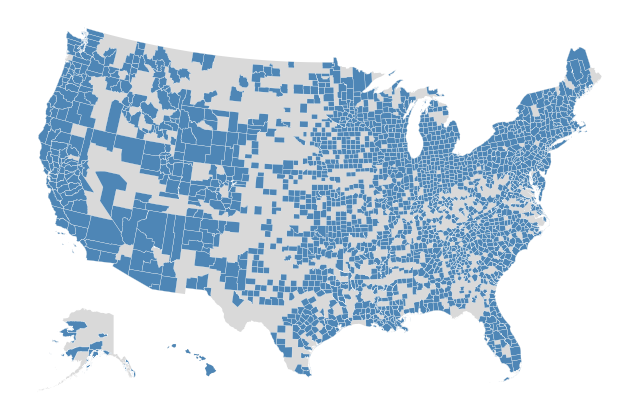

In [16]:
# -------------------------------------------------------
# Split counties into regions
# -------------------------------------------------------

not_conus=['02',  # Alaska
             '15',  # Hawaii
             '72',  # Puerto Rico
             '78',  # U.S. Virgin Islands
             '60',  # American Samoa
             '66',  # Guam
             '69']  # Northern Mariana Islands

usa = counties.to_crs("EPSG:5070") 
counties = counties.to_crs("EPSG:4269")

conus = usa[~usa["STATEFP"].isin(not_conus)]
alaska = counties[counties["STATEFP"] == "02"].copy()
hawaii = counties[counties["STATEFP"] == "15"].copy()

# Background polygons
conus_outline = conus[["geometry"]].dissolve()
alaska_outline = alaska[["geometry"]].dissolve()
hawaii_outline = hawaii[["geometry"]].dissolve()

# -------------------------------------------------------
# 1. Main CONUS map
# -------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 8))

# Background for CONUS as a single gray polygon
conus_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax,
    zorder=1
)

# Foreground county map
conus[conus['STCOFIPS'].isin(common_nodes)].plot(
    color='steelblue',
    linewidth=0.2,
    edgecolor='white',
    ax=ax,
    legend=False,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"}
)

ax.axis("off")

# -------------------------------------------------------
# 2. ALASKA INSET
# -------------------------------------------------------
ax_ak = inset_axes(
    ax,
    width="75%", height="75%",   # size relative to main axes
    loc="lower left",
    bbox_to_anchor=(0.00, 0.00, 0.3, 0.3),  # fine-tune position
    bbox_transform=ax.transAxes
)

ax_ak.axis("off")

# Background for Alaska
alaska_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax_ak,
    zorder=1
)

# Alaska counties with pagerank
alaska[alaska['STCOFIPS'].isin(common_nodes)].plot(
    color='steelblue',
    linewidth=0.3,
    edgecolor="white",
    ax=ax_ak,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"}
)

# Set xlim/ylim in EPSG:4269 coordinates (degrees)
ax_ak.set_xlim(-180, -129)
ax_ak.set_ylim(51, 72)


# -------------------------------------------------------
# 3. HAWAII INSET
# -------------------------------------------------------
ax_hi = inset_axes(
    ax, width="50%", height="50%", loc="lower left",
    bbox_to_anchor=(0.22, 0.02, 0.25, 0.25),  # position
    bbox_transform=ax.transAxes
)

ax_hi.set_axis_off()

hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi)
hawaii[hawaii['STCOFIPS'].isin(common_nodes)].plot(
    color='steelblue',
    linewidth=0,
    ax=ax_hi,
    alpha=0.95,
    missing_kwds={"color": "none"}
)

ax_hi.set_xlim(-161, -154)
ax_hi.set_ylim(18, 23)

plt.show()

In [17]:
### Separately for Job Industries (soc2)

# EXPERIENCE DATASET - TOTAL
df = pd.read_parquet("../data_generated/experience.parquet")

# TOP FIELDS
job_fields = [
    "Management",
    "Computer & Math",
    "Business & Finance",
    "Arts / Media / Design",
    "Education / Training",
    "Sales",
    "Legal",
    "Architecture & Engineering",
    "Healthcare Practitioners",
    "Sciences",
    "Social Services"
]

flow_store = []
hits_store = []

for field in tqdm(job_fields, desc="Merged SOC networks"):
    
    df_field = df[df["next_soc_broad"] == field].copy()

    df_win = (
        df_field[(df_field['next_start_date'] >= "2011-01-01") &
           (df_field['next_start_date'] <= "2022-12-31") &
           (df_field['next_job_zone'] >= 4.0)]
        .replace("nannan", np.nan)
        .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
        .assign(
            STCOFIPS=lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
            STCOFIPS_next=lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
        )
    )

    df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

    # aggregate flows across all years
    df_agg_soc2 = (
        df_win.groupby(['STCOFIPS', 'STCOFIPS_next'])
              .PERSON_ID.count()
              .reset_index()
              .rename(columns={'PERSON_ID': 'n'})
    )
    df_agg_soc2["job_field"] = field

    flow_store.append(df_agg_soc2)

    # build graph once per job field
    G = nx.DiGraph()
    G.add_weighted_edges_from(df_agg_soc2[["STCOFIPS", "STCOFIPS_next", "n"]].values)

    if len(G) == 0:
        continue

    hubs, auths = weighted_hits(G, weight="weight", normalized=True)
    pr = nx.pagerank(G, weight='weight')

    for node in G.nodes():
        hits_store.append({
            "job_field": field,
            "STCOFIPS": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

# final outputs
flows_soc2 = pd.concat(flow_store, ignore_index=True)
hits_soc2 = pd.DataFrame(hits_store)

# rank centralities
hits_soc2["rank_hub"]  = hits_soc2.groupby("job_field")["hub"]     .rank(method="dense", ascending=False)
hits_soc2["rank_auth"] = hits_soc2.groupby("job_field")["auth"]    .rank(method="dense", ascending=False)
hits_soc2["rank_page"] = hits_soc2.groupby("job_field")["pagerank"].rank(method="dense", ascending=False)

Merged SOC networks: 100%|██████████████████████| 11/11 [00:04<00:00,  2.63it/s]


In [18]:
# save all
hits_soc2.to_parquet("../data_generated/network_metrics/hits_soc2_1122.parquet")
flows_soc2.to_parquet("../data_generated/network_metrics/flows_soc2_1122.parquet")

In [19]:
### keep only counties present in all 4 top job fields (for now, to be able to compare across fields)

hits_soc2_reduced=hits_soc2[hits_soc2['job_field'].isin(['Management', 'Computer & Math', 'Business & Finance', 'Arts / Media / Design'])].copy()

valid_nodes = (
    hits_soc2_reduced.groupby("STCOFIPS")["job_field"]
    .count()
    .loc[lambda s: s == 4]
    .index
)

valid_nodes.nunique()

711

In [20]:
### Separately for Job Industries (soc2)

# EXPERIENCE DATASET - TOTAL
df = pd.read_parquet("../data_generated/experience.parquet")

# TOP FIELDS
job_fields = [
    "Management",
    "Computer & Math",
    "Business & Finance",
    "Arts / Media / Design",
    "Education / Training"
]

flow_store = []
hits_store = []

for field in tqdm(job_fields, desc="Merged SOC networks"):
    
    df_field = df[df["next_soc_broad"] == field].copy()

    df_win = (
        df_field[(df_field['next_start_date'] >= "2011-01-01") &
           (df_field['next_start_date'] <= "2022-12-31") &
           (df_field['next_job_zone'] >= 4.0)&
                 (df_field['STCOFIPS'].isin(valid_nodes)) &
                 (df_field['STCOFIPS_next'].isin(valid_nodes))]
        .replace("nannan", np.nan)
        .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
        .assign(
            STCOFIPS=lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
            STCOFIPS_next=lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
        )
    )

    df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

    # aggregate flows across all years
    df_agg_soc2 = (
        df_win.groupby(['STCOFIPS', 'STCOFIPS_next'])
              .PERSON_ID.count()
              .reset_index()
              .rename(columns={'PERSON_ID': 'n'})
    )
    df_agg_soc2["job_field"] = field

    flow_store.append(df_agg_soc2)

    # build graph once per job field
    G = nx.DiGraph()
    G.add_weighted_edges_from(df_agg_soc2[["STCOFIPS", "STCOFIPS_next", "n"]].values)

    if len(G) == 0:
        continue

    hubs, auths = weighted_hits(G, weight="weight", normalized=True)
    pr = nx.pagerank(G, weight='weight')

    for node in G.nodes():
        hits_store.append({
            "job_field": field,
            "STCOFIPS": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

# final outputs
flows_soc2 = pd.concat(flow_store, ignore_index=True)
hits_soc2 = pd.DataFrame(hits_store)

# rank centralities
hits_soc2["rank_hub"]  = hits_soc2.groupby("job_field")["hub"]     .rank(method="dense", ascending=False)
hits_soc2["rank_auth"] = hits_soc2.groupby("job_field")["auth"]    .rank(method="dense", ascending=False)
hits_soc2["rank_page"] = hits_soc2.groupby("job_field")["pagerank"].rank(method="dense", ascending=False)

Merged SOC networks: 100%|████████████████████████| 5/5 [00:02<00:00,  1.68it/s]


In [21]:
# save all
hits_soc2.to_parquet("../data_generated/network_metrics/hits_soc2_reduced_1122.parquet")
flows_soc2.to_parquet("../data_generated/network_metrics/flows_soc2_reduced_1122.parquet")

In [22]:
### Separately for Seniority

# EXPERIENCE DATASET - TOTAL
df = pd.read_parquet("../data_generated/experience.parquet")
df['next_job_zone'] = df.groupby('PERSON_ID')['Job Zone_final'].shift(-1)

flow_store = []
hits_store = []


for field in tqdm(df.next_seniority_group.unique(), desc="Merged SENIORITY networks"):
    
    df_field = df[df["next_seniority_group"] == field].copy()

    # Filter for time & HS transitions
    df_win = (
        df_field[(df_field['next_start_date'] >= "2011-01-01") &
           (df_field['next_start_date'] <= "2022-12-31") &
           (df_field['next_job_zone'] >= 4.0)]
        .replace("nannan", np.nan)
        .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
        .assign(
            STCOFIPS=lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
            STCOFIPS_next=lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
        )
    )

    df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

    # Aggregate flows across all years
    df_agg = (
        df_win.groupby(['STCOFIPS', 'STCOFIPS_next'])
              .PERSON_ID.count()
              .reset_index()
              .rename(columns={'PERSON_ID': 'n'})
    )
    df_agg["seniority"] = field

    flow_store.append(df_agg)

    # Build graph once per job field
    G = nx.DiGraph()
    G.add_weighted_edges_from(df_agg[["STCOFIPS", "STCOFIPS_next", "n"]].values)

    if len(G) == 0:
        continue

    hubs, auths = weighted_hits(G, weight="weight", normalized=True)
    pr = nx.pagerank(G, weight='weight')

    # Store centralities
    for node in G.nodes():
        hits_store.append({
            "seniority": field,
            "STCOFIPS": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

# final outputs
flows_soc2 = pd.concat(flow_store, ignore_index=True)
hits_soc2 = pd.DataFrame(hits_store)

# rank centralities
hits_soc2["rank_hub"]  = hits_soc2.groupby("seniority")["hub"]     .rank(method="dense", ascending=False)
hits_soc2["rank_auth"] = hits_soc2.groupby("seniority")["auth"]    .rank(method="dense", ascending=False)
hits_soc2["rank_page"] = hits_soc2.groupby("seniority")["pagerank"].rank(method="dense", ascending=False)


Merged SENIORITY networks: 100%|██████████████████| 4/4 [00:02<00:00,  1.33it/s]


In [23]:
hits_soc2.to_parquet("../data_generated/network_metrics/hits_seniority_1122.parquet")
flows_soc2.to_parquet("../data_generated/network_metrics/flows_seniority_1122.parquet")

In [24]:
### keep only counties present in all 3 seniority groups (for now, to be able to compare across groups)

valid_nodes = (
    hits_soc2.groupby("STCOFIPS")["seniority"]
    .count()
    .loc[lambda s: s == 3]
    .index
)

valid_nodes.nunique()

740

In [25]:
# separate for seniority - same set of counties
df = pd.read_parquet("../data_generated/experience.parquet")

flow_store = []
hits_store = []


for field in tqdm(df.next_seniority_group.unique(), desc="Merged SENIORITY networks"):
    
    df_field = df[df["next_seniority_group"] == field].copy()

    # Filter for time & HS transitions
    df_win = (
        df_field[(df_field['next_start_date'] >= "2011-01-01") &
                 (df_field['next_start_date'] <= "2022-12-31") &
                 (df_field['next_job_zone'] >= 4.0) &
                 (df_field['STCOFIPS'].isin(valid_nodes)) &
                 (df_field['STCOFIPS_next'].isin(valid_nodes))]
        .replace("nannan", np.nan)
        .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
        .assign(
            STCOFIPS=lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
            STCOFIPS_next=lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
        )
    )

    df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

    # Aggregate flows across all years
    df_agg = (
        df_win.groupby(['STCOFIPS', 'STCOFIPS_next'])
              .PERSON_ID.count()
              .reset_index()
              .rename(columns={'PERSON_ID': 'n'})
    )
    df_agg["seniority"] = field

    flow_store.append(df_agg)

    # Build graph once per job field
    G = nx.DiGraph()
    G.add_weighted_edges_from(df_agg[["STCOFIPS", "STCOFIPS_next", "n"]].values)

    if len(G) == 0:
        continue

    hubs, auths = weighted_hits(G, weight="weight", normalized=True)
    pr = nx.pagerank(G, weight='weight')

    # Store centralities
    for node in G.nodes():
        hits_store.append({
            "seniority": field,
            "STCOFIPS": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

# final outputs
flows_soc2 = pd.concat(flow_store, ignore_index=True)
hits_soc2 = pd.DataFrame(hits_store)

# rank centralities
hits_soc2["rank_hub"]  = hits_soc2.groupby("seniority")["hub"]     .rank(method="dense", ascending=False)
hits_soc2["rank_auth"] = hits_soc2.groupby("seniority")["auth"]    .rank(method="dense", ascending=False)
hits_soc2["rank_page"] = hits_soc2.groupby("seniority")["pagerank"].rank(method="dense", ascending=False)


Merged SENIORITY networks: 100%|██████████████████| 4/4 [00:02<00:00,  1.45it/s]


In [26]:
hits_soc2.to_parquet("../data_generated/network_metrics/hits_seniority_reduced_1122.parquet")
flows_soc2.to_parquet("../data_generated/network_metrics/flows_seniority_reduced_1122.parquet")

In [27]:
### three-year periods

## EXP
df = pd.read_parquet("../data_generated/experience.parquet")

years = list(range(2011, 2023, 3))
flow_store = []
hits_store = []

for y in years:
    y1 = f"{y}-01-01"
    y2 = f"{y+2}-12-31"

    df_win = (
        df[(df['next_start_date'] >= y1) &
           (df['next_start_date'] <=  y2) &
           (df['next_job_zone'] >= 4.0)] 
        .replace("nannan", np.nan) # for STCOFIPS and STCOFIPS_next
        .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
        .assign(
            STCOFIPS = lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
            STCOFIPS_next = lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
        )
    )

    # remove self-loops here
    df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

    print(df_win.PERSON_ID.nunique())

    # aggregate weights
    df_agg = (
        df_win.groupby(['STCOFIPS','STCOFIPS_next'])
              .PERSON_ID.count()
              .reset_index()
              .rename(columns={'PERSON_ID':'n'})
    )
    df_agg["window"] = f"{y}-{y+2}"

    # store for later
    flow_store.append(df_agg)

    # build directed graph
    G = nx.DiGraph()
    for _, row in df_agg.iterrows():
        G.add_edge(row["STCOFIPS"], row["STCOFIPS_next"], weight=row["n"])

    # compute centralities
    hubs, auths = weighted_hits(G, weight='weight', normalized=True)
    pr = nx.pagerank(G, weight='weight')

    # store
    for node in G.nodes():
        hits_store.append({
            "window": f"{y}-{y+2}",
            "STCOFIPS": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

hits_exp = pd.DataFrame(hits_store)
flows_exp = pd.concat(flow_store, ignore_index=True)

# ranks per window
hits_exp["rank_hub"]  = hits_exp.groupby("window")["hub"]      .rank("dense", ascending=False)
hits_exp["rank_auth"] = hits_exp.groupby("window")["auth"]     .rank("dense", ascending=False)
hits_exp["rank_page"] = hits_exp.groupby("window")["pagerank"] .rank("dense", ascending=False)

37115
51239
51082
32486


In [28]:
unique_nodes_by_window = (
    flows_exp.groupby('window')
    .apply(lambda g: pd.unique(pd.concat([g['STCOFIPS'], g['STCOFIPS_next']])))
)

exp_nodes_dict = {w: list(nodes) for w, nodes in unique_nodes_by_window.items()}

# how many unique nodes per window
for w, nodes in exp_nodes_dict.items():
    print(f"{w}: {len(nodes)} unique nodes")

2011-2013: 1501 unique nodes
2014-2016: 1650 unique nodes
2017-2019: 1617 unique nodes
2020-2022: 1385 unique nodes


In [29]:
# intersection of nodes across all windows
common_nodes = set.intersection(
    *(set(nodes) for nodes in exp_nodes_dict.values())
)

common_nodes_dict = {
    w: sorted(common_nodes) for w in exp_nodes_dict.keys()
}

print(f"Nodes present in all periods: {len(common_nodes)}")


Nodes present in all periods: 1027


In [30]:
## IRS
flows_irs_clean["year"]=flows_irs_clean["window"].astype(str).str[-2:].astype(int) + 2000

flow_store = []
hits_store = []

for y in years:
    y1 = y
    y2 = y+2

    df_win = (flows_irs_clean[(flows_irs_clean['year'] >= y1) & 
                              (flows_irs_clean['year'] <= y2)  &
                              (flows_irs_clean['STCOFIPS'].isin(exp_nodes_dict[f'{y1}-{y2}'])) & 
                              (flows_irs_clean['STCOFIPS_next'].isin(exp_nodes_dict[f'{y1}-{y2}']))] 
             )

    # aggregate weights
    df_agg = (
        df_win.groupby(['STCOFIPS','STCOFIPS_next'])
              .in_n_persons.sum()
              .reset_index()
    )
    df_agg["window"] = f"{y}-{y+2}"

    flow_store.append(df_agg)

    # build directed graph
    G = nx.DiGraph()
    for _, r in df_agg.iterrows():
        o = r["STCOFIPS"]; d = r["STCOFIPS_next"]; w = r["in_n_persons"]
        G.add_edge(o,d, weight=w)

    # compute centralities
    hubs, auths = weighted_hits(G, weight='weight', normalized=True)
    pr = nx.pagerank(G, weight='weight')

    # store
    for node in G.nodes():
        hits_store.append({
            "window": f"{y}-{y+2}",
            "STCOFIPS": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })


hits_irs = pd.DataFrame(hits_store)
flows_irs = pd.concat(flow_store, ignore_index=True)

# ranks per window
hits_irs["rank_hub"]  = hits_irs.groupby("window")["hub"]      .rank("dense", ascending=False)
hits_irs["rank_auth"] = hits_irs.groupby("window")["auth"]     .rank("dense", ascending=False)
hits_irs["rank_page"] = hits_irs.groupby("window")["pagerank"] .rank("dense", ascending=False)

In [31]:
# save all
hits_exp.to_parquet("../data_generated/network_metrics/hits_exp_3y.parquet")
flows_exp.to_parquet("../data_generated/network_metrics/flows_exp_3y.parquet")
hits_irs.to_parquet("../data_generated/network_metrics/hits_irs_3y.parquet")
flows_irs.to_parquet("../data_generated/network_metrics/flows_irs_3y.parquet")

## CBSA-level Networks (2011-2022)

In [32]:
df = pd.read_parquet("../data_generated/experience.parquet")

y1 = "2011-01-01"
y2 = "2022-12-31"

df_win = (
    df[(df['next_start_date'] >= y1) &
       (df['next_start_date'] <=  y2) &
       (df['next_job_zone'] >= 4.0)]
    .replace("nannan", np.nan) # for STCOFIPS and STCOFIPS_next
    .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
    .assign(
        STCOFIPS = lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
        STCOFIPS_next = lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
    )
)

# remove self-loops here
df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

print(df_win.PERSON_ID.nunique())

128006


In [33]:
cbsa = load_cbsa()

In [34]:
df_agg_exp_final=pd.read_parquet("../data_generated/network_metrics/flows_exp_1122.parquet")
df_agg_irs_final=pd.read_parquet("../data_generated/network_metrics/flows_irs_1122.parquet")

df_agg_exp_final=df_agg_exp_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], on='STCOFIPS', how='left')
df_agg_exp_final=df_agg_exp_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='STCOFIPS_next', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])

df_agg_irs_final=df_agg_irs_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], on='STCOFIPS', how='left')
df_agg_irs_final=df_agg_irs_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='STCOFIPS_next', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])

In [35]:
cbsa_exp=df_agg_exp_final.groupby(['CBSA Code', 'CBSA Title', 'CBSA Code_next', 'CBSA Title_next']).n.sum().reset_index()
cbsa_irs=df_agg_irs_final.groupby(['CBSA Code', 'CBSA Title', 'CBSA Code_next', 'CBSA Title_next']).n.sum().reset_index()

cbsa_exp=cbsa_exp[cbsa_exp['CBSA Code']!=cbsa_exp['CBSA Code_next']].reset_index(drop=True)
cbsa_irs=cbsa_irs[cbsa_irs['CBSA Code']!=cbsa_irs['CBSA Code_next']].reset_index(drop=True)

In [36]:
common_nodes = pd.Index(cbsa_exp['CBSA Code'].dropna().unique()) \
    .intersection(cbsa_irs['CBSA Code'].dropna().unique()) \
    .intersection(cbsa_exp['CBSA Code_next'].dropna().unique()) \
    .intersection(cbsa_irs['CBSA Code_next'].dropna().unique())

len(common_nodes)

803

In [37]:
# =============================================================================
# BUILD EXP NETWORK
# =============================================================================

G_exp = nx.DiGraph()
G_exp.add_weighted_edges_from(
    cbsa_exp[["CBSA Code", "CBSA Code_next", "n"]].values
)

# compute centralities
hubs_exp, auth_exp = weighted_hits(G_exp, weight="weight", normalized=True)
pr_exp = nx.pagerank(G_exp, weight='weight')

hits_exp_single = pd.DataFrame({
    "CBSA": common_nodes,
    "hub":      [hubs_exp.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_exp.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_exp.get(n, np.nan) for n in common_nodes]
})

hits_exp_single["rank_hub"]  = hits_exp_single["hub"].rank(method="dense", ascending=False)
hits_exp_single["rank_auth"] = hits_exp_single["auth"].rank(method="dense", ascending=False)
hits_exp_single["rank_page"] = hits_exp_single["pagerank"].rank(method="dense", ascending=False)

print("Final EXP nodes:", len(hits_exp_single))

# =============================================================================
# BUILD IRS NETWORK
# =============================================================================

G_irs = nx.DiGraph()
G_irs.add_weighted_edges_from(
    cbsa_irs[["CBSA Code", "CBSA Code_next", "n"]].values
)

# compute centralities
hubs_irs, auth_irs = weighted_hits(G_irs, weight="weight", normalized=True)
pr_irs = nx.pagerank(G_irs, weight='weight')

hits_irs_single = pd.DataFrame({
    "CBSA": common_nodes,
    "hub":      [hubs_irs.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_irs.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_irs.get(n, np.nan) for n in common_nodes]
})

hits_irs_single["rank_hub"]  = hits_irs_single["hub"].rank(method="dense", ascending=False)
hits_irs_single["rank_auth"] = hits_irs_single["auth"].rank(method="dense", ascending=False)
hits_irs_single["rank_page"] = hits_irs_single["pagerank"].rank(method="dense", ascending=False)

print("Final IRS nodes:", len(hits_irs_single))


Final EXP nodes: 803
Final IRS nodes: 803


In [38]:
# save all
hits_exp_single.to_parquet("../data_generated/network_metrics/cbsa_hits_exp_1122.parquet")
cbsa_exp.to_parquet("../data_generated/network_metrics/cbsa_flows_exp_1122.parquet")

hits_irs_single.to_parquet("../data_generated/network_metrics/cbsa_hits_irs_1122.parquet")
cbsa_irs.to_parquet("../data_generated/network_metrics/cbsa_flows_irs_1122.parquet")

### Probabilistic assignment for counties

In [3]:
### LODES

# load + build county-to-county shares (LODES)
path = "../data_loaded/LODES/lodes_od_aggregated_by_county_2016.csv"

df = pd.read_csv(path, dtype={'STCOFIPS_w':str,'STCOFIPS_h':str})

#SE01 = jobs with earnings $1,250/month or less
#SE02 = jobs with earnings $1,251/month to $3,333/month
#SE03 = jobs with earnings greater than $3,333/month
# SI01 (Goods Producing): NAICS 11, 21, 23, 31–33
# SI02 (Trade/Transportation/Utilities): NAICS 42, 44–45, 48–49, 22
# SI03 (All Other Services): the remaining 2-digit NAICS sectors

# keep only relevant columns
df = df[
    ["STCOFIPS_h", "STCOFIPS_w", "SE03", "SI03"]
].copy()

# ensure numeric
df["SI03"] = pd.to_numeric(df["SI03"], errors="coerce")
df["SE03"] = pd.to_numeric(df["SE03"], errors="coerce")

flow_col = "SI03"
# 1) p(home | work): normalise by work county (destination)
work_total = df.groupby("STCOFIPS_w")[flow_col].transform("sum")
commuting_probs = (
    df.assign(
        total_inflow=work_total,
        share=df[flow_col] / work_total
    )
    .rename(columns={"STCOFIPS": "STCOFIPS_h", "STCOFIPS_next": "STCOFIPS_w", flow_col: "SI03"})
    .loc[:, ["STCOFIPS_h", "STCOFIPS_w", "SI03", "share"]]
)

# optional: drop any weird rows where totals are 0
commuting_probs = commuting_probs.replace([np.inf, -np.inf], np.nan).dropna(subset=["share"])

In [9]:
# How many people working in Manhattan live in surrounding counties?

# Manhattan = New York County, NY
manhattan_fips = "36061"

manhattan_commuters = (
    commuting_probs
    .loc[commuting_probs["STCOFIPS_w"] == manhattan_fips]
    .copy()
)

manhattan_commuters = (
    manhattan_commuters
    .sort_values("SI03", ascending=False)
    .reset_index(drop=True)
)

manhattan_commuters["percentage"] = manhattan_commuters["share"] * 100

county_names = {
    "36061": "New York County (Manhattan), NY",
    "36047": "Kings County (Brooklyn), NY",
    "36081": "Queens County, NY",
    "36005": "Bronx County, NY",
    "36059": "Nassau County, NY",
    "36119": "Westchester County, NY",
    "34017": "Hudson County, NJ",
    "34003": "Bergen County, NJ",
    "36103": "Suffolk County, NY",
    "36085": "Richmond County (Staten Island), NY",
    "34013": "Essex County, NJ",
    "09001": "Fairfield County, CT",
    "34023": "Middlesex County, NJ",
    "34025": "Monmouth County, NJ",
    "34039": "Union County, NJ",
    "36087": "Rockland County, NY",
    "36071": "Orange County, NY",
    "34027": "Morris County, NJ",
    "34031": "Passaic County, NJ",
    "36027": "Dutchess County, NY"
}

table["Home county"] = (
    table["Home county FIPS"]
    .map(county_names)
    .fillna(table["Home county FIPS"])
)

table_display = table[
    ["Home county", "Home county FIPS", "Workers", "Share (%)"]
]

display(
    table_display.head(10).style
    .format({
        "Workers": "{:,.0f}",
        "Share (%)": "{:.2f}%"
    })
    .bar(subset=["Share (%)"])
    .hide(axis="index")
    .set_caption(
        "Where Manhattan's external SI03 workforce lives (top-10)"
    )
)

Home county,Home county FIPS,Workers,Share (%)
"New York County (Manhattan), NY",36061,"497,420",23.25%
"Kings County (Brooklyn), NY",36047,"401,549",18.77%
"Queens County, NY",36081,"325,774",15.23%
"Bronx County, NY",36005,"186,864",8.74%
"Nassau County, NY",36059,"101,624",4.75%
"Westchester County, NY",36119,"83,282",3.89%
"Hudson County, NJ",34017,"77,534",3.62%
"Bergen County, NJ",34003,"65,050",3.04%
"Suffolk County, NY",36103,"56,449",2.64%
"Richmond County (Staten Island), NY",36085,"54,423",2.54%


In [12]:
# How many people working in San Francisco County live in surrounding counties?

# San Francisco = San Francisco County, CA
sf_fips = "06075"

sf_commuters = (
    commuting_probs
    .loc[commuting_probs["STCOFIPS_w"] == sf_fips]
    .copy()
)

sf_commuters = (
    sf_commuters
    .sort_values("SI03", ascending=False)
    .reset_index(drop=True)
)

sf_commuters["percentage"] = sf_commuters["share"] * 100

county_names_sf = {
    "06075": "San Francisco County, CA",
    "06001": "Alameda County, CA",
    "06013": "Contra Costa County, CA",
    "06081": "San Mateo County, CA",
    "06085": "Santa Clara County, CA",
    "06041": "Marin County, CA",
    "06097": "Sonoma County, CA",
    "06055": "Napa County, CA",
    "06095": "Solano County, CA",
    "06077": "San Joaquin County, CA",
    "06099": "Stanislaus County, CA",
    "06067": "Sacramento County, CA",
    "06087": "Santa Cruz County, CA",
    "06069": "San Benito County, CA",
    "06007": "Butte County, CA",
    "06113": "Yolo County, CA",
    "06061": "Placer County, CA",
    "06057": "Nevada County, CA",
    "06017": "El Dorado County, CA",
    "06053": "Monterey County, CA",
    "06037": "Los Angeles County, CA"
}

table_sf = (
    sf_commuters[
        ["STCOFIPS_h", "SI03", "percentage"]
    ]
    .rename(columns={
        "STCOFIPS_h": "Home county FIPS",
        "SI03": "Workers",
        "percentage": "Share (%)"
    })
)

table_sf["Home county"] = (
    table_sf["Home county FIPS"]
    .map(county_names_sf)
    .fillna(table_sf["Home county FIPS"])
)

table_display_sf = table_sf[
    ["Home county", "Home county FIPS", "Workers", "Share (%)"]
]

display(
    table_display_sf.head(10).style
    .format({
        "Workers": "{:,.0f}",
        "Share (%)": "{:.2f}%"
    })
    .bar(subset=["Share (%)"])
    .hide(axis="index")
    .set_caption(
        "Where San Francisco County's SI03 workforce lives (top-10)"
    )
)

Home county,Home county FIPS,Workers,Share (%)
"San Francisco County, CA",06075,"244,996",41.26%
"Alameda County, CA",06001,"88,566",14.92%
"San Mateo County, CA",06081,"70,046",11.80%
"Contra Costa County, CA",06013,"50,337",8.48%
"Santa Clara County, CA",06085,"28,584",4.81%
"Marin County, CA",06041,"23,474",3.95%
"Los Angeles County, CA",06037,"15,568",2.62%
"Sacramento County, CA",06067,"10,116",1.70%
"Solano County, CA",06095,"9,177",1.55%
"Sonoma County, CA",06097,"8,145",1.37%


In [40]:
# commuting_probs: columns [work_county, home_county, workers, share]
min_share = 0.05 # only keep home counties that account for at least 5% of the work county's inflow (to reduce noise and speed up sampling)

cp = (
    commuting_probs[commuting_probs["share"] >= min_share]
    .copy()
)

cp["share"] = (
    cp["share"] /
    cp.groupby("STCOFIPS_w")["share"].transform("sum"))

# build lookup tables: for each work county store arrays of homes and probs
home_lookup = (
    cp.groupby("STCOFIPS_w")
      .apply(lambda g: pd.DataFrame({
          "home": [g["STCOFIPS_h"].to_numpy()],
          "p":    [g["share"].to_numpy()]
      }))
      .reset_index(level=1, drop=True)
)

def draw_home(work_series, rng):
    homes_out = []

    for w in work_series:
        if w in home_lookup.index:
            row = home_lookup.loc[w]
            homes = row["home"]
            probs = row["p"]
            homes_out.append(rng.choice(homes, p=probs))
        else:
            # if no commuting data exists, fall back to same county
            homes_out.append(w)

    return pd.Series(homes_out, index=work_series.index)

In [41]:
rng1 = np.random.default_rng(123) # set seed for reproducibility
rng2 = np.random.default_rng(456) # different seed for next job county to ensure independent draws

# infer home for current job county
df_win["home_from_job"] = draw_home(df_win["STCOFIPS"], rng1)

# infer home for next job county
df_win["home_from_next_job"] = draw_home(df_win["STCOFIPS_next"], rng2)

In [42]:
# aggregate over all years
df_agg_exp = (
    df_win.groupby(['home_from_job', 'home_from_next_job'])
          .PERSON_ID.count()
          .reset_index()
          .rename(columns={'PERSON_ID': 'n'})
)

# remove self-loops
df_agg_exp = df_agg_exp[df_agg_exp["home_from_job"] != df_agg_exp["home_from_next_job"]]

# node set before cleaning
exp_nodes_initial = set(
    pd.concat([df_agg_exp['home_from_job'], df_agg_exp['home_from_next_job']], ignore_index=True)
)
print("EXP nodes initial:", len(exp_nodes_initial))


# =============================================================================
# 2. IRS DATA
# =============================================================================

irs_nodes_initial = set(
    pd.concat([flows_irs_clean['STCOFIPS'], flows_irs_clean['STCOFIPS_next']], ignore_index=True)
)
print("IRS nodes initial:", len(irs_nodes_initial))


# =============================================================================
# 3. CLEAN NODE SETS
# =============================================================================

common_nodes = exp_nodes_initial & irs_nodes_initial 
common_nodes = sorted(common_nodes)

df_exp_clean = df_agg_exp[
    df_agg_exp["home_from_job"].isin(common_nodes) &
    df_agg_exp["home_from_next_job"].isin(common_nodes)
]

df_irs_clean = flows_irs_clean[
    flows_irs_clean["STCOFIPS"].isin(common_nodes) &
    flows_irs_clean["STCOFIPS_next"].isin(common_nodes)
]

exp_nodes_cleaned = set(
    pd.concat([df_exp_clean['home_from_job'], df_exp_clean['home_from_next_job']], ignore_index=True)
)
irs_nodes_cleaned = set(
    pd.concat([df_irs_clean['STCOFIPS'], df_irs_clean['STCOFIPS_next']], ignore_index=True)
)

common_nodes = exp_nodes_cleaned & irs_nodes_cleaned 
common_nodes = sorted(common_nodes)

# actually common nodes now
df_exp_clean = df_agg_exp[
    df_agg_exp["home_from_job"].isin(common_nodes) &
    df_agg_exp["home_from_next_job"].isin(common_nodes)
]

df_irs_clean = flows_irs_clean[
    flows_irs_clean["STCOFIPS"].isin(common_nodes) &
    flows_irs_clean["STCOFIPS_next"].isin(common_nodes)
]

df_irs_clean = (
    df_irs_clean.groupby(['STCOFIPS', 'STCOFIPS_next'])
                .in_n_persons.sum()
                .reset_index()
                .rename(columns={'in_n_persons': 'n'})
)

print("COMMON nodes (after cleaning):", len(common_nodes))


# =============================================================================
# Once again, to ensure
# =============================================================================

df_agg_exp_final = df_exp_clean[
    df_exp_clean["home_from_job"].isin(common_nodes) &
    df_exp_clean["home_from_next_job"].isin(common_nodes)
].copy()

df_agg_irs_final = df_irs_clean[
    df_irs_clean["STCOFIPS"].isin(common_nodes) &
    df_irs_clean["STCOFIPS_next"].isin(common_nodes)
].copy()

print("EXP edges after final filtering:", len(df_agg_exp_final))
print("IRS edges after final filtering:", len(df_agg_irs_final))

# =============================================================================
# BUILD EXP NETWORK
# =============================================================================

G_exp = nx.DiGraph()
G_exp.add_weighted_edges_from(
    df_agg_exp[["home_from_job", "home_from_next_job", "n"]].values
)

# compute centralities
hubs_exp, auth_exp = weighted_hits(G_exp, weight="weight", normalized=True)
pr_exp = nx.pagerank(G_exp, weight='weight')

hits_exp_single = pd.DataFrame({
    "STCOFIPS": common_nodes,
    "hub":      [hubs_exp.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_exp.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_exp.get(n, np.nan) for n in common_nodes]
})

hits_exp_single["rank_hub"]  = hits_exp_single["hub"].rank(method="dense", ascending=False)
hits_exp_single["rank_auth"] = hits_exp_single["auth"].rank(method="dense", ascending=False)
hits_exp_single["rank_page"] = hits_exp_single["pagerank"].rank(method="dense", ascending=False)

print("Final EXP nodes:", len(hits_exp_single))

# =============================================================================
# BUILD IRS NETWORK
# =============================================================================

G_irs = nx.DiGraph()
G_irs.add_weighted_edges_from(
    df_agg_irs_final[["STCOFIPS", "STCOFIPS_next", "n"]].values
)

# compute centralities
hubs_irs, auth_irs = weighted_hits(G_irs, weight="weight", normalized=True)
pr_irs = nx.pagerank(G_irs, weight='weight')

hits_irs_single = pd.DataFrame({
    "STCOFIPS": common_nodes,
    "hub":      [hubs_irs.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_irs.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_irs.get(n, np.nan) for n in common_nodes]
})

hits_irs_single["rank_hub"]  = hits_irs_single["hub"].rank(method="dense", ascending=False)
hits_irs_single["rank_auth"] = hits_irs_single["auth"].rank(method="dense", ascending=False)
hits_irs_single["rank_page"] = hits_irs_single["pagerank"].rank(method="dense", ascending=False)

print("Final IRS nodes:", len(hits_irs_single))

# =============================================================================
# Print results and shapes
# =============================================================================

print("\n================== SUMMARY ==================")
print("EXP nodes initial:", len(exp_nodes_initial))
print("IRS nodes initial:", len(irs_nodes_initial))
print("EXP nodes after cleaning:", len(exp_nodes_cleaned))
print("IRS nodes after cleaning:", len(irs_nodes_cleaned))
print("COMMON FINAL nodes:", len(common_nodes))
print("EXP network final size:", hits_exp_single.shape)
print("IRS network final size:", hits_irs_single.shape)
print("=============================================\n")


EXP nodes initial: 2149
IRS nodes initial: 3100
COMMON nodes (after cleaning): 2140
EXP edges after final filtering: 55646
IRS edges after final filtering: 98960
Final EXP nodes: 2140
Final IRS nodes: 2140

================== SUMMARY ==================
EXP nodes initial: 2149
IRS nodes initial: 3100
EXP nodes after cleaning: 2144
IRS nodes after cleaning: 2140
COMMON FINAL nodes: 2140
EXP network final size: (2140, 7)
IRS network final size: (2140, 7)



In [43]:
# save all
hits_exp_single.to_parquet("../data_generated/network_metrics/hits_exp_1122_lodes.parquet")
df_agg_exp_final.to_parquet("../data_generated/network_metrics/flows_exp_1122_lodes.parquet")

hits_irs_single.to_parquet("../data_generated/network_metrics/hits_irs_1122_lodes.parquet")
df_agg_irs_final.to_parquet("../data_generated/network_metrics/flows_irs_1122_lodes.parquet")

In [44]:
exp_nodes_cleaned = set(
    pd.concat([df_agg_exp_final['home_from_job'], df_agg_exp_final['home_from_next_job']], ignore_index=True)
)

In [45]:
### Separately for Job Industries (soc2)

# EXPERIENCE DATASET - TOTAL
df = pd.read_parquet("../data_generated/experience.parquet")

# TOP FIELDS
job_fields = [
    "Management",
    "Computer & Math",
    "Business & Finance",
    "Arts / Media / Design",
    "Education / Training",
    "Sales",
    "Legal",
    "Architecture & Engineering",
    "Healthcare Practitioners",
    "Sciences",
    "Social Services"
]

flow_store = []
hits_store = []

for field in tqdm(job_fields, desc="Merged SOC networks"):
    
    df_field = df[df["next_soc_broad"] == field].copy()

    df_win = (
        df_field[(df_field['next_start_date'] >= "2011-01-01") &
           (df_field['next_start_date'] <= "2022-12-31") &
           (df_field['next_job_zone'] >= 4.0)]
        .replace("nannan", np.nan)
        .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
        .assign(
            STCOFIPS=lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
            STCOFIPS_next=lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
        )
    )

    df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

    # infer home for current job county
    df_win["home_from_job"] = draw_home(df_win["STCOFIPS"], rng1)
    # infer home for next job county
    df_win["home_from_next_job"] = draw_home(df_win["STCOFIPS_next"], rng2)

    df_win = df_win[df_win["home_from_job"] != df_win["home_from_next_job"]]

    # aggregate flows across all years
    df_agg_soc2 = (
        df_win.groupby(['home_from_job', 'home_from_next_job'])
              .PERSON_ID.count()
              .reset_index()
              .rename(columns={'PERSON_ID': 'n'})
    )
    df_agg_soc2["job_field"] = field

    flow_store.append(df_agg_soc2)

    # build graph once per job field
    G = nx.DiGraph()
    G.add_weighted_edges_from(df_agg_soc2[["home_from_job", "home_from_next_job", "n"]].values)

    if len(G) == 0:
        continue

    hubs, auths = weighted_hits(G, weight="weight", normalized=True)
    pr = nx.pagerank(G, weight='weight')

    for node in G.nodes():
        hits_store.append({
            "job_field": field,
            "STCOFIPS": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

# final outputs
flows_soc2 = pd.concat(flow_store, ignore_index=True)
hits_soc2 = pd.DataFrame(hits_store)

# rank centralities
hits_soc2["rank_hub"]  = hits_soc2.groupby("job_field")["hub"]     .rank(method="dense", ascending=False)
hits_soc2["rank_auth"] = hits_soc2.groupby("job_field")["auth"]    .rank(method="dense", ascending=False)
hits_soc2["rank_page"] = hits_soc2.groupby("job_field")["pagerank"].rank(method="dense", ascending=False)

Merged SOC networks: 100%|██████████████████████| 11/11 [00:28<00:00,  2.60s/it]


In [46]:
# save all
hits_soc2.to_parquet("../data_generated/network_metrics/hits_soc2_1122_lodes.parquet")
flows_soc2.to_parquet("../data_generated/network_metrics/flows_soc2_1122_lodes.parquet")

In [47]:
### Separately for Seniority

# EXPERIENCE DATASET - TOTAL
df = pd.read_parquet("../data_generated/experience.parquet")
df['next_job_zone'] = df.groupby('PERSON_ID')['Job Zone_final'].shift(-1)

flow_store = []
hits_store = []


for field in tqdm(df.next_seniority_group.unique(), desc="Merged SENIORITY networks"):
    
    df_field = df[df["next_seniority_group"] == field].copy()

    # Filter for time & HS transitions
    df_win = (
        df_field[(df_field['next_start_date'] >= "2011-01-01") &
           (df_field['next_start_date'] <= "2022-12-31") &
           (df_field['next_job_zone'] >= 4.0)]
        .replace("nannan", np.nan)
        .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
        .assign(
            STCOFIPS=lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
            STCOFIPS_next=lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
        )
    )

    df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

    # infer home for current job county
    df_win["home_from_job"] = draw_home(df_win["STCOFIPS"], rng1)
    # infer home for next job county
    df_win["home_from_next_job"] = draw_home(df_win["STCOFIPS_next"], rng2)

    df_win = df_win[df_win["home_from_job"] != df_win["home_from_next_job"]]


    # Aggregate flows across all years
    df_agg = (
        df_win.groupby(['home_from_job', 'home_from_next_job'])
              .PERSON_ID.count()
              .reset_index()
              .rename(columns={'PERSON_ID': 'n'})
    )
    df_agg["seniority"] = field

    flow_store.append(df_agg)

    # Build graph once per job field
    G = nx.DiGraph()
    G.add_weighted_edges_from(df_agg[["home_from_job", "home_from_next_job", "n"]].values)

    if len(G) == 0:
        continue

    hubs, auths = weighted_hits(G, weight="weight", normalized=True)
    pr = nx.pagerank(G, weight='weight')

    # Store centralities
    for node in G.nodes():
        hits_store.append({
            "seniority": field,
            "STCOFIPS": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

# final outputs
flows_soc2 = pd.concat(flow_store, ignore_index=True)
hits_soc2 = pd.DataFrame(hits_store)

# rank centralities
hits_soc2["rank_hub"]  = hits_soc2.groupby("seniority")["hub"]     .rank(method="dense", ascending=False)
hits_soc2["rank_auth"] = hits_soc2.groupby("seniority")["auth"]    .rank(method="dense", ascending=False)
hits_soc2["rank_page"] = hits_soc2.groupby("seniority")["pagerank"].rank(method="dense", ascending=False)

Merged SENIORITY networks: 100%|██████████████████| 4/4 [00:26<00:00,  6.65s/it]


In [48]:
hits_soc2.to_parquet("../data_generated/network_metrics/hits_seniority_1122_lodes.parquet")
flows_soc2.to_parquet("../data_generated/network_metrics/flows_seniority_1122_lodes.parquet")

### CBSA from reassigned counties (used as cbsa2)

In [49]:
cbsa = load_cbsa()


In [50]:
df_agg_exp_final=pd.read_parquet("../data_generated/network_metrics/flows_exp_1122_lodes.parquet")
df_agg_irs_final=pd.read_parquet("../data_generated/network_metrics/flows_irs_1122_lodes.parquet")

df_agg_exp_final=df_agg_exp_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='home_from_job', right_on='STCOFIPS', how='left')
df_agg_exp_final=df_agg_exp_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='home_from_next_job', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])

df_agg_irs_final=df_agg_irs_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], on='STCOFIPS', how='left')
df_agg_irs_final=df_agg_irs_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='STCOFIPS_next', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])

In [51]:
cbsa_exp=df_agg_exp_final.groupby(['CBSA Code', 'CBSA Title', 'CBSA Code_next', 'CBSA Title_next']).n.sum().reset_index()
cbsa_irs=df_agg_irs_final.groupby(['CBSA Code', 'CBSA Title', 'CBSA Code_next', 'CBSA Title_next']).n.sum().reset_index()

cbsa_exp=cbsa_exp[cbsa_exp['CBSA Code']!=cbsa_exp['CBSA Code_next']].reset_index(drop=True)
cbsa_irs=cbsa_irs[cbsa_irs['CBSA Code']!=cbsa_irs['CBSA Code_next']].reset_index(drop=True)

In [52]:
common_nodes = pd.Index(cbsa_exp['CBSA Code'].dropna().unique()) \
    .intersection(cbsa_irs['CBSA Code'].dropna().unique()) \
    .intersection(cbsa_exp['CBSA Code_next'].dropna().unique()) \
    .intersection(cbsa_irs['CBSA Code_next'].dropna().unique())

len(common_nodes)

# not entirely sure if pure overlap is a good idea here - but i think so

806

In [53]:
# =============================================================================
# BUILD EXP NETWORK
# =============================================================================

G_exp = nx.DiGraph()
G_exp.add_weighted_edges_from(
    cbsa_exp[["CBSA Code", "CBSA Code_next", "n"]].values
)

# compute centralities
hubs_exp, auth_exp = weighted_hits(G_exp, weight="weight", normalized=True)
pr_exp = nx.pagerank(G_exp, weight='weight')

hits_exp_single = pd.DataFrame({
    "CBSA": common_nodes,
    "hub":      [hubs_exp.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_exp.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_exp.get(n, np.nan) for n in common_nodes]
})

hits_exp_single["rank_hub"]  = hits_exp_single["hub"].rank(method="dense", ascending=False)
hits_exp_single["rank_auth"] = hits_exp_single["auth"].rank(method="dense", ascending=False)
hits_exp_single["rank_page"] = hits_exp_single["pagerank"].rank(method="dense", ascending=False)

print("Final EXP nodes:", len(hits_exp_single))

# =============================================================================
# BUILD IRS NETWORK
# =============================================================================

G_irs = nx.DiGraph()
G_irs.add_weighted_edges_from(
    cbsa_irs[["CBSA Code", "CBSA Code_next", "n"]].values
)

# compute centralities
hubs_irs, auth_irs = weighted_hits(G_irs, weight="weight", normalized=True)
pr_irs = nx.pagerank(G_irs, weight='weight')

hits_irs_single = pd.DataFrame({
    "CBSA": common_nodes,
    "hub":      [hubs_irs.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_irs.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_irs.get(n, np.nan) for n in common_nodes]
})

hits_irs_single["rank_hub"]  = hits_irs_single["hub"].rank(method="dense", ascending=False)
hits_irs_single["rank_auth"] = hits_irs_single["auth"].rank(method="dense", ascending=False)
hits_irs_single["rank_page"] = hits_irs_single["pagerank"].rank(method="dense", ascending=False)

print("Final IRS nodes:", len(hits_irs_single))


Final EXP nodes: 806
Final IRS nodes: 806


In [54]:
# save all
hits_exp_single.to_parquet("../data_generated/network_metrics/cbsa2_hits_exp_1122.parquet")
cbsa_exp.to_parquet("../data_generated/network_metrics/cbsa2_flows_exp_1122.parquet")

hits_irs_single.to_parquet("../data_generated/network_metrics/cbsa2_hits_irs_1122.parquet")
cbsa_irs.to_parquet("../data_generated/network_metrics/cbsa2_flows_irs_1122.parquet")

In [55]:
df_agg_soc2_final=pd.read_parquet("../data_generated/network_metrics/flows_soc2_1122_lodes.parquet")
df_agg_sen_final=pd.read_parquet("../data_generated/network_metrics/flows_seniority_1122_lodes.parquet")

df_agg_soc2_final=df_agg_soc2_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='home_from_job', right_on='STCOFIPS', how='left')
df_agg_soc2_final=df_agg_soc2_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='home_from_next_job', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])

df_agg_sen_final=df_agg_sen_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='home_from_job', right_on='STCOFIPS', how='left')
df_agg_sen_final=df_agg_sen_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='home_from_next_job', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])

In [56]:
cbsa_soc2=df_agg_soc2_final.groupby(['CBSA Code', 'CBSA Title', 'CBSA Code_next', 'CBSA Title_next', 'job_field']).n.sum().reset_index()
cbsa_sen=df_agg_sen_final.groupby(['CBSA Code', 'CBSA Title', 'CBSA Code_next', 'CBSA Title_next', 'seniority']).n.sum().reset_index()

cbsa_soc2=cbsa_soc2[cbsa_soc2['CBSA Code']!=cbsa_soc2['CBSA Code_next']].reset_index(drop=True)
cbsa_sen=cbsa_sen[cbsa_sen['CBSA Code']!=cbsa_sen['CBSA Code_next']].reset_index(drop=True)

In [57]:
len(common_nodes)

806

In [58]:
# =============================================================================
# BUILD SOC2 NETWORKS
# =============================================================================

flow_store = []
hits_store = []

for field in tqdm(job_fields, desc="Merged SOC networks"):

    df_field=cbsa_soc2[cbsa_soc2['job_field']==field].copy()
    flow_store.append(df_field)
    
    G_soc2 = nx.DiGraph()
    G_soc2.add_weighted_edges_from(
        df_field[["CBSA Code", "CBSA Code_next", "n"]].values
    )
    
    # compute centralities
    hubs, auths = weighted_hits(G_soc2, weight="weight", normalized=True)
    pr = nx.pagerank(G_soc2, weight='weight')
    
    for node in G_soc2.nodes():
        hits_store.append({
            "job_field": field,
            "CBSA": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

# final outputs
flows_soc2 = pd.concat(flow_store, ignore_index=True)
hits_soc2 = pd.DataFrame(hits_store)

# rank centralities
hits_soc2["rank_hub"]  = hits_soc2.groupby("job_field")["hub"]     .rank(method="dense", ascending=False)
hits_soc2["rank_auth"] = hits_soc2.groupby("job_field")["auth"]    .rank(method="dense", ascending=False)
hits_soc2["rank_page"] = hits_soc2.groupby("job_field")["pagerank"].rank(method="dense", ascending=False)

# save all
hits_soc2.to_parquet("../data_generated/network_metrics/cbsa2_soc2_hits_exp_1122.parquet")
flows_soc2.to_parquet("../data_generated/network_metrics/cbsa2_soc2_flows_1122.parquet")

# =============================================================================
# BUILD SEN NETWORKS
# =============================================================================

flow_store = []
hits_store = []

for field in tqdm(cbsa_sen.seniority.unique(), desc="Merged SENIORITY networks"):

    df_field=cbsa_sen[cbsa_sen['seniority']==field].copy()
    flow_store.append(df_field)
    
    G_soc2 = nx.DiGraph()
    G_soc2.add_weighted_edges_from(
        df_field[["CBSA Code", "CBSA Code_next", "n"]].values
    )
    
    # compute centralities
    hubs, auths = weighted_hits(G_soc2, weight="weight", normalized=True)
    pr = nx.pagerank(G_soc2, weight='weight')
    
    for node in G_soc2.nodes():
        hits_store.append({
            "seniority": field,
            "CBSA": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

# final outputs
flows_soc2 = pd.concat(flow_store, ignore_index=True)
hits_soc2 = pd.DataFrame(hits_store)

# rank centralities
hits_soc2["rank_hub"]  = hits_soc2.groupby("seniority")["hub"]     .rank(method="dense", ascending=False)
hits_soc2["rank_auth"] = hits_soc2.groupby("seniority")["auth"]    .rank(method="dense", ascending=False)
hits_soc2["rank_page"] = hits_soc2.groupby("seniority")["pagerank"].rank(method="dense", ascending=False)

# save all
hits_soc2.to_parquet("../data_generated/network_metrics/cbsa2_seniority_hits_exp_1122.parquet")
flows_soc2.to_parquet("../data_generated/network_metrics/cbsa2_seniority_flows_1122.parquet")


Merged SENIORITY networks: 100%|██████████████████| 3/3 [00:00<00:00,  6.67it/s]


### CBSA without reassignment (used as cbsa)

In [59]:
cbsa = load_cbsa()

In [60]:
df_agg_exp_final=pd.read_parquet("../data_generated/network_metrics/flows_exp_1122.parquet")
df_agg_irs_final=pd.read_parquet("../data_generated/network_metrics/flows_irs_1122.parquet")

df_agg_exp_final=df_agg_exp_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='STCOFIPS', right_on='STCOFIPS', how='left')
df_agg_exp_final=df_agg_exp_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='STCOFIPS_next', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])

df_agg_irs_final=df_agg_irs_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], on='STCOFIPS', how='left')
df_agg_irs_final=df_agg_irs_final.merge(cbsa[['CBSA Code','CBSA Title','STCOFIPS']], left_on='STCOFIPS_next', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])

In [61]:
cbsa_exp=df_agg_exp_final.groupby(['CBSA Code', 'CBSA Title', 'CBSA Code_next', 'CBSA Title_next']).n.sum().reset_index()
cbsa_irs=df_agg_irs_final.groupby(['CBSA Code', 'CBSA Title', 'CBSA Code_next', 'CBSA Title_next']).n.sum().reset_index()

cbsa_exp=cbsa_exp[cbsa_exp['CBSA Code']!=cbsa_exp['CBSA Code_next']].reset_index(drop=True)
cbsa_irs=cbsa_irs[cbsa_irs['CBSA Code']!=cbsa_irs['CBSA Code_next']].reset_index(drop=True)

In [62]:
common_nodes = pd.Index(cbsa_exp['CBSA Code'].dropna().unique()) \
    .intersection(cbsa_irs['CBSA Code'].dropna().unique()) \
    .intersection(cbsa_exp['CBSA Code_next'].dropna().unique()) \
    .intersection(cbsa_irs['CBSA Code_next'].dropna().unique())

len(common_nodes)

# not entirely sure if pure overlap is a good idea here - but i think so

803

In [63]:
# =============================================================================
# BUILD EXP NETWORK
# =============================================================================

G_exp = nx.DiGraph()
G_exp.add_weighted_edges_from(
    cbsa_exp[["CBSA Code", "CBSA Code_next", "n"]].values
)

# compute centralities
hubs_exp, auth_exp = weighted_hits(G_exp, weight="weight", normalized=True)
pr_exp = nx.pagerank(G_exp, weight='weight')

hits_exp_single = pd.DataFrame({
    "CBSA": common_nodes,
    "hub":      [hubs_exp.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_exp.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_exp.get(n, np.nan) for n in common_nodes]
})

hits_exp_single["rank_hub"]  = hits_exp_single["hub"].rank(method="dense", ascending=False)
hits_exp_single["rank_auth"] = hits_exp_single["auth"].rank(method="dense", ascending=False)
hits_exp_single["rank_page"] = hits_exp_single["pagerank"].rank(method="dense", ascending=False)

print("Final EXP nodes:", len(hits_exp_single))

# =============================================================================
# BUILD IRS NETWORK
# =============================================================================

G_irs = nx.DiGraph()
G_irs.add_weighted_edges_from(
    cbsa_irs[["CBSA Code", "CBSA Code_next", "n"]].values
)

# compute centralities
hubs_irs, auth_irs = weighted_hits(G_irs, weight="weight", normalized=True)
pr_irs = nx.pagerank(G_irs, weight='weight')

hits_irs_single = pd.DataFrame({
    "CBSA": common_nodes,
    "hub":      [hubs_irs.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_irs.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_irs.get(n, np.nan) for n in common_nodes]
})

hits_irs_single["rank_hub"]  = hits_irs_single["hub"].rank(method="dense", ascending=False)
hits_irs_single["rank_auth"] = hits_irs_single["auth"].rank(method="dense", ascending=False)
hits_irs_single["rank_page"] = hits_irs_single["pagerank"].rank(method="dense", ascending=False)

print("Final IRS nodes:", len(hits_irs_single))


Final EXP nodes: 803
Final IRS nodes: 803


In [64]:
# save all
hits_exp_single.to_parquet("../data_generated/network_metrics/cbsa_hits_exp_1122.parquet")
cbsa_exp.to_parquet("../data_generated/network_metrics/cbsa_flows_exp_1122.parquet")

hits_irs_single.to_parquet("../data_generated/network_metrics/cbsa_hits_irs_1122.parquet")
cbsa_irs.to_parquet("../data_generated/network_metrics/cbsa_flows_irs_1122.parquet")

### CBSA - Create networks per time window (2011-2013, 2014-2016, 2017-2019, 2020-2022)

In [65]:
## EXP
df = pd.read_parquet("../data_generated/experience.parquet")

years = list(range(2011, 2023, 3))
flow_store = []
hits_store = []

for y in years:
    y1 = f"{y}-01-01"
    y2 = f"{y+2}-12-31"

    df_win = (
        df[(df['next_start_date'] >= y1) &
           (df['next_start_date'] <=  y2) &
           (df['next_job_zone'] >= 4.0)]
        .replace("nannan", np.nan) # for STCOFIPS and STCOFIPS_next
        .dropna(subset=['STCOFIPS', 'STCOFIPS_next'])
        .assign(
            STCOFIPS = lambda x: x['STCOFIPS'].astype(str).str.zfill(5),
            STCOFIPS_next = lambda x: x['STCOFIPS_next'].astype(str).str.zfill(5)
        )
    )

    # remove self-loops here
    df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]

    print(df_win.PERSON_ID.nunique())
    
    # infer home for current job county
    df_win["home_from_job"] = draw_home(df_win["STCOFIPS"], rng1)
    # infer home for next job county
    df_win["home_from_next_job"] = draw_home(df_win["STCOFIPS_next"], rng2)

    # aggregate weights
    df_agg = (
        df_win.groupby(['home_from_job','home_from_next_job'])
              .PERSON_ID.count()
              .reset_index()
              .rename(columns={'PERSON_ID':'n'})
    )

    # aggregate to CBSA
    df_agg=df_agg.merge(cbsa[['CBSA Code','STCOFIPS']], left_on='home_from_job', right_on='STCOFIPS', how='left')
    df_agg=df_agg.merge(cbsa[['CBSA Code','STCOFIPS']], left_on='home_from_next_job', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])
    df_agg = (
        df_agg.groupby(['CBSA Code','CBSA Code_next'])
              .n.sum()
              .reset_index()
    )

    # remove self-loops here
    df_agg = df_agg[df_agg["CBSA Code"] != df_agg["CBSA Code_next"]]

    df_agg["window"] = f"{y}-{y+2}"

    # store for later
    flow_store.append(df_agg)

    # build directed graph
    G = nx.DiGraph()
    G.add_weighted_edges_from(df_agg[["CBSA Code", "CBSA Code_next", "n"]].values)

    # compute centralities
    hubs, auths = weighted_hits(G, weight='weight', normalized=True)
    pr = nx.pagerank(G, weight='weight')

    # store
    for node in G.nodes():
        hits_store.append({
            "window": f"{y}-{y+2}",
            "CBSA": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })

hits_exp = pd.DataFrame(hits_store)
flows_exp = pd.concat(flow_store, ignore_index=True)

# ranks per window
hits_exp["rank_hub"]  = hits_exp.groupby("window")["hub"]      .rank("dense", ascending=False)
hits_exp["rank_auth"] = hits_exp.groupby("window")["auth"]     .rank("dense", ascending=False)
hits_exp["rank_page"] = hits_exp.groupby("window")["pagerank"] .rank("dense", ascending=False)

37115
51239
51082
32486


In [66]:
unique_nodes_by_window = (
    flows_exp.groupby('window')
    .apply(lambda g: pd.unique(pd.concat([g['CBSA Code'], g['CBSA Code_next']])))
)

exp_nodes_dict = {w: list(nodes) for w, nodes in unique_nodes_by_window.items()}

# how many unique nodes per window
for w, nodes in exp_nodes_dict.items():
    print(f"{w}: {len(nodes)} unique nodes")

2011-2013: 739 unique nodes
2014-2016: 785 unique nodes
2017-2019: 774 unique nodes
2020-2022: 719 unique nodes


In [67]:
# intersection of nodes across all windows
common_nodes = set.intersection(
    *(set(nodes) for nodes in exp_nodes_dict.values())
)

common_nodes_dict = {
    w: sorted(common_nodes) for w in exp_nodes_dict.keys()
}

print(f"Nodes present in all periods: {len(common_nodes)}")


Nodes present in all periods: 603


In [68]:
## IRS
flows_irs_clean["year"]=flows_irs_clean["window"].astype(str).str[-2:].astype(int) + 2000

flow_store = []
hits_store = []

for y in years:
    y1 = y
    y2 = y+2

    df_win = (flows_irs_clean[(flows_irs_clean['year'] >= y1) & 
                              (flows_irs_clean['year'] <= y2)])

    # remove self-loops here
    df_win = df_win[df_win["STCOFIPS"] != df_win["STCOFIPS_next"]]
    
    # aggregate weights
    df_agg = (
        df_win.groupby(['STCOFIPS','STCOFIPS_next'])
        .in_n_persons.sum()
        .reset_index().rename(columns={'in_n_persons':'n'})
    )

    # aggregate to CBSA
    df_agg=df_agg.merge(cbsa[['CBSA Code','STCOFIPS']], left_on='STCOFIPS', right_on='STCOFIPS', how='left')
    df_agg=df_agg.merge(cbsa[['CBSA Code','STCOFIPS']], left_on='STCOFIPS_next', right_on='STCOFIPS', how='left',
                                       suffixes=['', '_next'])
    df_agg = (
        df_agg.groupby(['CBSA Code','CBSA Code_next'])
              .n.sum()
              .reset_index()
    )
    
    df_agg = (df_agg[(df_agg['CBSA Code'].isin(exp_nodes_dict[f'{y1}-{y2}'])) & 
                     (df_agg['CBSA Code_next'].isin(exp_nodes_dict[f'{y1}-{y2}']))]
             )

    # remove self-loops here
    df_agg = df_agg[df_agg["CBSA Code"] != df_agg["CBSA Code_next"]]

    df_agg["window"] = f"{y}-{y+2}"

    flow_store.append(df_agg)

    # build directed graph
    G = nx.DiGraph()
    for _, r in df_agg.iterrows():
        o = r["CBSA Code"]; d = r["CBSA Code_next"]; w = r["n"]
        G.add_edge(o,d, weight=w)

    # compute centralities
    hubs, auths = weighted_hits(G, weight='weight', normalized=True)
    pr = nx.pagerank(G, weight='weight')

    # store
    for node in G.nodes():
        hits_store.append({
            "window": f"{y}-{y+2}",
            "CBSA": node,
            "hub": hubs.get(node, np.nan),
            "auth": auths.get(node, np.nan),
            "pagerank": pr.get(node, np.nan)
        })


hits_irs = pd.DataFrame(hits_store)
flows_irs = pd.concat(flow_store, ignore_index=True)

# ranks per window
hits_irs["rank_hub"]  = hits_irs.groupby("window")["hub"]      .rank("dense", ascending=False)
hits_irs["rank_auth"] = hits_irs.groupby("window")["auth"]     .rank("dense", ascending=False)
hits_irs["rank_page"] = hits_irs.groupby("window")["pagerank"] .rank("dense", ascending=False)

In [69]:
print(f"Nodes present in all periods: {len(common_nodes)}")

Nodes present in all periods: 603


In [70]:
# save all
hits_exp.to_parquet("../data_generated/network_metrics/cbsa2_hits_exp_3y.parquet")
flows_exp.to_parquet("../data_generated/network_metrics/cbsa2_flows_exp_3y.parquet")
hits_irs.to_parquet("../data_generated/network_metrics/cbsa2_hits_irs_3y.parquet")
flows_irs.to_parquet("../data_generated/network_metrics/cbsa2_flows_irs_3y.parquet")

### For SI: pooled 2011-2019 network

Sums the three-year-window edge lists (`cbsa2_flows_exp_3y.parquet` / `cbsa2_flows_irs_3y.parquet`) over the 2011-2013, 2014-2016 and 2017-2019 windows to get the pooled 2011-2019 CBSA network, then applies `weighted_hits()` as defined above.

The per-window `draw_home()` draws saved in the `_3y` files are reused, so the pooled network is the sum of the per-window outputs under the same LODES commuting-probability model.

In [5]:
WINDOWS_1119 = ["2011-2013", "2014-2016", "2017-2019"]

def build_pooled_network(flows_3y_path, windows):
    flows = pd.read_parquet(flows_3y_path)
    sub = flows[flows["window"].isin(windows)]
    return sub.groupby(["CBSA Code", "CBSA Code_next"], as_index=False)["n"].sum()

cbsa_exp = build_pooled_network("../data_generated/network_metrics/cbsa2_flows_exp_3y.parquet", WINDOWS_1119)
cbsa_irs = build_pooled_network("../data_generated/network_metrics/cbsa2_flows_irs_3y.parquet", WINDOWS_1119)

common_nodes = (
    pd.Index(cbsa_exp['CBSA Code'].dropna().unique())
    .intersection(cbsa_irs['CBSA Code'].dropna().unique())
    .intersection(cbsa_exp['CBSA Code_next'].dropna().unique())
    .intersection(cbsa_irs['CBSA Code_next'].dropna().unique())
)

print("cbsa_exp edges:", len(cbsa_exp), " cbsa_irs edges:", len(cbsa_irs), " common_nodes:", len(common_nodes))

cbsa_exp edges: 20309  cbsa_irs edges: 35102  common_nodes: 781


In [6]:
# =============================================================================
# BUILD EXP NETWORK
# =============================================================================

G_exp = nx.DiGraph()
G_exp.add_weighted_edges_from(
    cbsa_exp[["CBSA Code", "CBSA Code_next", "n"]].values
)

hubs_exp, auth_exp = weighted_hits(G_exp, weight="weight", normalized=True)
pr_exp = nx.pagerank(G_exp, weight='weight')

hits_exp_single = pd.DataFrame({
    "CBSA": common_nodes,
    "hub":      [hubs_exp.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_exp.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_exp.get(n, np.nan) for n in common_nodes]
})

hits_exp_single["rank_hub"]  = hits_exp_single["hub"].rank(method="dense", ascending=False)
hits_exp_single["rank_auth"] = hits_exp_single["auth"].rank(method="dense", ascending=False)
hits_exp_single["rank_page"] = hits_exp_single["pagerank"].rank(method="dense", ascending=False)

print("Final EXP nodes:", len(hits_exp_single))

# =============================================================================
# BUILD IRS NETWORK
# =============================================================================

G_irs = nx.DiGraph()
G_irs.add_weighted_edges_from(
    cbsa_irs[["CBSA Code", "CBSA Code_next", "n"]].values
)

hubs_irs, auth_irs = weighted_hits(G_irs, weight="weight", normalized=True)
pr_irs = nx.pagerank(G_irs, weight='weight')

hits_irs_single = pd.DataFrame({
    "CBSA": common_nodes,
    "hub":      [hubs_irs.get(n, np.nan) for n in common_nodes],
    "auth":     [auth_irs.get(n, np.nan) for n in common_nodes],
    "pagerank": [pr_irs.get(n, np.nan) for n in common_nodes]
})

hits_irs_single["rank_hub"]  = hits_irs_single["hub"].rank(method="dense", ascending=False)
hits_irs_single["rank_auth"] = hits_irs_single["auth"].rank(method="dense", ascending=False)
hits_irs_single["rank_page"] = hits_irs_single["pagerank"].rank(method="dense", ascending=False)

print("Final IRS nodes:", len(hits_irs_single))

Final EXP nodes: 781
Final IRS nodes: 781


In [7]:
# save all
hits_exp_single.to_parquet("../data_generated/network_metrics/cbsa2_hits_exp_1119.parquet")
cbsa_exp.to_parquet("../data_generated/network_metrics/cbsa2_flows_exp_1119.parquet")

hits_irs_single.to_parquet("../data_generated/network_metrics/cbsa2_hits_irs_1119.parquet")
cbsa_irs.to_parquet("../data_generated/network_metrics/cbsa2_flows_irs_1119.parquet")

## Network statistics

In [71]:
import heapq

def weighted_core_numbers(G, weight="weight"):
    """
    Efficient weighted k-core decomposition using a min-heap.
    """
    H = G.copy()

    strength = {
        n: H.degree(n, weight=weight)
        for n in H.nodes()
    }

    heap = [(s, n) for n, s in strength.items()]
    heapq.heapify(heap)

    core = {}  # node → core level (tau)
    removed = set()

    while heap:
        s, n = heapq.heappop(heap)

        if n in removed:
            continue

        # record removal
        core[n] = s
        removed.add(n)

        # removing n affects its neighbors' strengths
        for nbr in list(H.neighbors(n)):
            if nbr in removed:
                continue

            # decrease neighbor strength by edge weights
            w = H[n][nbr].get(weight, 1.0)
            strength[nbr] -= w

            # push updated value into heap
            heapq.heappush(heap, (strength[nbr], nbr))

        for nbr in list(H.predecessors(n)):
            if nbr in removed:
                continue

            w = H[nbr][n].get(weight, 1.0)
            strength[nbr] -= w
            heapq.heappush(heap, (strength[nbr], nbr))

        H.remove_node(n)

    return core


def weighted_core_ratio_fast(G, weight="weight"):
    core = weighted_core_numbers(G, weight=weight)
    vals = np.array(list(core.values()), dtype=float)

    mean_core = vals.mean()
    max_core = vals.max()

    return max_core / mean_core if mean_core > 0 else np.nan


In [72]:
def compute_mobility_network_stats(df, 
                                   origin_col="STCOFIPS", 
                                   dest_col="STCOFIPS_next", 
                                   weight_col="n",
                                   window_col=None):
    """
    Compute network statistics for county-to-county mobility flows.
    
    Parameters
    ----------
    df : pandas.DataFrame
        Flow dataset.
    origin_col, dest_col : str
        Column names for origin and destination counties.
    weight_col : str
        Column name for edge weights.
    window_col : str or None
        If provided, compute stats per window; otherwise single run.

    Returns
    -------
    pandas.DataFrame with network statistics.
    """

    def compute_stats(sub_df, label):
        G = nx.DiGraph()
        G.add_weighted_edges_from(
            sub_df[[origin_col, dest_col, weight_col]].values
        )

        n_nodes = G.number_of_nodes()
        n_edges = G.number_of_edges()

        # Avoid division errors for empty networks
        if n_nodes == 0:
            return {"window": label, "nodes": 0}

        density = nx.density(G)

        avg_in_deg = sum(dict(G.in_degree()).values()) / n_nodes
        avg_out_deg = sum(dict(G.out_degree()).values()) / n_nodes

        avg_in_strength = sum(dict(G.in_degree(weight="weight")).values()) / n_nodes
        avg_out_strength = sum(dict(G.out_degree(weight="weight")).values()) / n_nodes

        # unweighted and weighted clustering per node
        clustering = nx.average_clustering(G.to_undirected())
        clustering_w_dict = nx.clustering(G.to_undirected(), weight="weight")
        # average weighted clustering
        avg_w_clustering = float(np.mean(list(clustering_w_dict.values())))

        largest_wcc = max(len(c) for c in nx.weakly_connected_components(G)) / n_nodes

        assort = nx.degree_pearson_correlation_coefficient(G)

        # node strengths
        for n in G.nodes():
            G.nodes[n]["strength"] = G.degree(n, weight="weight")

        num_assort = nx.numeric_assortativity_coefficient(G, "strength")

        # unweighted core ratio (topology only)
        core_nums = nx.core_number(G.to_undirected())
        avg_core = sum(core_nums.values()) / len(core_nums)
        max_core = max(core_nums.values())
        core_ratio = max_core / avg_core if avg_core > 0 else 0

        # weighted core ratio (flow magnitudes)
        w_core_ratio = weighted_core_ratio_fast(G, weight="weight")

        return {
            "window": label,
            "nodes": n_nodes,
            "edges": n_edges,
            "density": density,
            "avg_in_deg": avg_in_deg,
            "avg_out_deg": avg_out_deg,
            "avg_in_strength": avg_in_strength,
            "avg_out_strength": avg_out_strength,
            "avg_clustering": clustering,
            "avg_w_clustering": avg_w_clustering,
            "largest_component_share": largest_wcc,
            "assortativity": assort,
            "strength_assortativity": num_assort,
            "core_ratio": core_ratio,
            "w_core_ratio": w_core_ratio
        }

    # CASE 1: compute metrics for each window
    if window_col and window_col in df.columns:
        stats = []
        for label, group in df.groupby(window_col):
            stats.append(compute_stats(group, label))
        return pd.DataFrame(stats)

    # CASE 2: compute a single set of metrics for full dataset
    else:
        return pd.DataFrame([compute_stats(df, "full_dataset")])


In [73]:
flows_irs=pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_irs_1122.parquet")
flows_exp=pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_exp_1122.parquet")

stats_irs_full = compute_mobility_network_stats(flows_irs, origin_col="CBSA Code", dest_col="CBSA Code_next") 
stats_exp_full = compute_mobility_network_stats(flows_exp, origin_col="CBSA Code", dest_col="CBSA Code_next") 

stats_irs_full["dataset"] = "irs"
stats_exp_full["dataset"] = "exp"

stats_combined = pd.concat([stats_irs_full, stats_exp_full], ignore_index=True)
stats_combined.round(3)

,window,nodes,edges,density,avg_in_deg,avg_out_deg,avg_in_strength,avg_out_strength,avg_clustering,avg_w_clustering,largest_component_share,assortativity,strength_assortativity,core_ratio,w_core_ratio,dataset
0,full_dataset,879,36892,0.048,41.970,41.970,72700.933,72700.933,0.737,0.000,1.0,-0.204,-0.155,2.645,21.068,irs
1,full_dataset,878,22786,0.030,25.952,25.952,192.092,192.092,0.653,0.001,1.0,-0.375,-0.195,2.796,29.710,exp


In [74]:
flows_irs=pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_irs_3y.parquet")
flows_exp=pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_exp_3y.parquet")

stats_irs_full = compute_mobility_network_stats(flows_irs, window_col='window',
                                               origin_col="CBSA Code", dest_col="CBSA Code_next")
stats_exp_full = compute_mobility_network_stats(flows_exp, window_col='window',
                                               origin_col="CBSA Code", dest_col="CBSA Code_next")

stats_irs_full["dataset"] = "irs"
stats_exp_full["dataset"] = "exp"

stats_combined = pd.concat([stats_irs_full, stats_exp_full], ignore_index=True)
stats_combined.round(3)

,window,nodes,edges,density,avg_in_deg,avg_out_deg,avg_in_strength,avg_out_strength,avg_clustering,avg_w_clustering,largest_component_share,assortativity,strength_assortativity,core_ratio,w_core_ratio,dataset
0,2011-2013,739,33152,0.061,44.861,44.861,16446.963,16446.963,0.746,0.001,1.000,-0.214,-0.161,2.416,18.095,irs
1,2014-2016,785,17610,0.029,22.433,22.433,17818.073,17818.073,0.727,0.001,1.000,-0.147,-0.127,3.094,20.736,irs
2,2017-2019,774,20946,0.035,27.062,27.062,23763.579,23763.579,0.731,0.001,1.000,-0.140,-0.125,2.976,18.450,irs
3,2020-2022,718,19733,0.038,27.483,27.483,24659.478,24659.478,0.743,0.001,1.000,-0.159,-0.135,2.825,17.281,irs
4,2011-2013,739,9232,0.017,12.493,12.493,48.503,48.503,0.498,0.003,0.997,-0.340,-0.229,3.504,24.349,exp
5,2014-2016,785,11320,0.018,14.420,14.420,64.173,64.173,0.541,0.002,0.997,-0.349,-0.221,3.302,25.618,exp
6,2017-2019,774,10929,0.018,14.120,14.120,64.792,64.792,0.536,0.002,1.000,-0.341,-0.210,3.529,26.099,exp
7,2020-2022,719,8064,0.016,11.216,11.216,44.615,44.615,0.501,0.003,0.989,-0.343,-0.214,3.850,26.897,exp


In [75]:
flows_exp=pd.read_parquet("../data_generated/network_metrics/cbsa2_soc2_flows_1122.parquet")

stats_exp_full = compute_mobility_network_stats(flows_exp, window_col='job_field', origin_col="CBSA Code", dest_col="CBSA Code_next") 

stats_exp_full["dataset"] = "exp"

stats_exp_full.round(3)

,window,nodes,edges,density,avg_in_deg,avg_out_deg,avg_in_strength,avg_out_strength,avg_clustering,avg_w_clustering,largest_component_share,assortativity,strength_assortativity,core_ratio,w_core_ratio,dataset
0,Architecture & Engineering,276,1024,0.013,3.710,3.710,5.986,5.986,0.216,0.008,0.986,-0.175,-0.156,3.196,11.361,exp
1,Arts / Media / Design,544,3473,0.012,6.384,6.384,15.243,15.243,0.357,0.004,1.000,-0.256,-0.178,3.892,24.208,exp
2,Business & Finance,677,6183,0.014,9.133,9.133,25.192,25.192,0.428,0.007,0.994,-0.277,-0.214,4.041,17.426,exp
3,Computer & Math,607,7471,0.020,12.308,12.308,63.234,63.234,0.568,0.002,0.997,-0.382,-0.227,3.414,28.529,exp
4,Education / Training,485,2923,0.012,6.027,6.027,13.237,13.237,0.333,0.005,0.975,-0.244,-0.204,3.849,17.451,exp
5,Healthcare Practitioners,383,1335,0.009,3.486,3.486,4.358,4.358,0.193,0.030,0.963,-0.081,-0.076,3.778,6.425,exp
6,Legal,146,342,0.016,2.342,2.342,3.000,3.000,0.166,0.030,0.877,-0.139,-0.129,2.903,6.000,exp
7,Management,754,9768,0.017,12.955,12.955,54.653,54.653,0.513,0.003,0.997,-0.359,-0.227,3.556,23.073,exp
8,Sales,392,2141,0.014,5.462,5.462,11.125,11.125,0.344,0.015,0.985,-0.276,-0.217,3.980,12.764,exp
9,Sciences,208,568,0.013,2.731,2.731,3.567,3.567,0.186,0.027,0.933,-0.100,-0.086,3.004,7.569,exp


In [76]:
flows_exp=pd.read_parquet("../data_generated/network_metrics/cbsa2_seniority_flows_1122.parquet")

stats_exp_full = compute_mobility_network_stats(flows_exp, window_col='seniority', origin_col="CBSA Code", dest_col="CBSA Code_next") 

stats_exp_full["dataset"] = "exp"

stats_exp_full.round(3)

,window,nodes,edges,density,avg_in_deg,avg_out_deg,avg_in_strength,avg_out_strength,avg_clustering,avg_w_clustering,largest_component_share,assortativity,strength_assortativity,core_ratio,w_core_ratio,dataset
0,Early-career,551,4411,0.015,8.005,8.005,24.169,24.169,0.417,0.003,0.989,-0.293,-0.206,3.803,26.149,exp
1,Mid-career,849,15736,0.022,18.535,18.535,105.913,105.913,0.599,0.001,1.000,-0.369,-0.213,3.089,27.693,exp
2,Senior leadership,567,4555,0.014,8.034,8.034,24.005,24.005,0.446,0.005,0.988,-0.316,-0.221,3.831,21.370,exp


## Bootstrapping statistics

In [77]:
from joblib import Parallel, delayed
import numpy as np
import pandas as pd
import networkx as nx
from tqdm import tqdm

# ---------------------------------------------------------------------
# helpers
# ---------------------------------------------------------------------

def _build_digraph(df, origin_col, dest_col, weight_col):
    G = nx.DiGraph()
    edges = df[[origin_col, dest_col, weight_col]].to_numpy()
    G.add_weighted_edges_from(edges)  # weight attribute name becomes "weight"
    return G

def _build_graph_undirected(df, origin_col, dest_col, weight_col):
    G = nx.Graph()
    edges = df[[origin_col, dest_col, weight_col]].to_numpy()
    G.add_weighted_edges_from(edges)
    return G

# ---------------------------------------------------------------------
# metrics (now column-name agnostic)
# ---------------------------------------------------------------------

def metric_strength_assort(df, origin_col="STCOFIPS", dest_col="STCOFIPS_next", weight_col="n"):
    G = _build_digraph(df, origin_col, dest_col, weight_col)

    for node in G.nodes():
        G.nodes[node]["strength"] = G.degree(node, weight="weight")

    return nx.numeric_assortativity_coefficient(G, "strength")


def metric_w_core_ratio(df, origin_col="STCOFIPS", dest_col="STCOFIPS_next", weight_col="n"):
    G = _build_digraph(df, origin_col, dest_col, weight_col)
    return weighted_core_ratio_fast(G, weight="weight")


def metric_avg_w_clustering(df, origin_col="STCOFIPS", dest_col="STCOFIPS_next", weight_col="n"):
    G = _build_graph_undirected(df, origin_col, dest_col, weight_col)
    cl = nx.clustering(G, weight="weight")
    return float(np.mean(list(cl.values()))) if len(cl) else np.nan


def metric_degree_assort(df, origin_col="STCOFIPS", dest_col="STCOFIPS_next", weight_col="n"):
    G = _build_digraph(df, origin_col, dest_col, weight_col)
    return nx.degree_pearson_correlation_coefficient(G)


def metric_core_ratio(df, origin_col="STCOFIPS", dest_col="STCOFIPS_next", weight_col="n"):
    G = _build_digraph(df, origin_col, dest_col, weight_col)

    if G.number_of_nodes() == 0:
        return np.nan

    core_nums = nx.core_number(G.to_undirected())
    avg_core = sum(core_nums.values()) / len(core_nums) if core_nums else 0
    max_core = max(core_nums.values()) if core_nums else 0

    return (max_core / avg_core) if avg_core > 0 else 0


# ---------------------------------------------------------------------
# bootstrap single draw (column-name agnostic)
# ---------------------------------------------------------------------

def bootstrap_destination_shuffle_once_all(
    df_edges,
    seed,
    origin_col="STCOFIPS",
    dest_col="STCOFIPS_next",
    weight_col="n"
):
    rng = np.random.RandomState(seed)
    out = []

    # destination shuffle per origin
    for origin, group in df_edges.groupby(origin_col, sort=False):
        dests = group[dest_col].to_numpy()
        weights = group[weight_col].to_numpy()

        total_out = int(weights.sum())
        if total_out <= 0:
            continue

        probs = weights / total_out
        sampled = rng.choice(dests, size=total_out, p=probs)

        uniq, cnts = np.unique(sampled, return_counts=True)
        out.append(pd.DataFrame({
            origin_col: origin,
            dest_col: uniq,
            weight_col: cnts
        }))

    if not out:
        # empty bootstrap network -> return NaNs
        return {
            "strength_assort": np.nan,
            "degree_assort":   np.nan,
            "w_core_ratio":    np.nan,
            "core_ratio":      np.nan,
            "avg_w_clust":     np.nan
        }

    df_boot = pd.concat(out, ignore_index=True)

    # compute all metrics
    return {
        "strength_assort": metric_strength_assort(df_boot, origin_col, dest_col, weight_col),
        "degree_assort":   metric_degree_assort(df_boot, origin_col, dest_col, weight_col),
        "w_core_ratio":    metric_w_core_ratio(df_boot, origin_col, dest_col, weight_col),
        "core_ratio":      metric_core_ratio(df_boot, origin_col, dest_col, weight_col),
        "avg_w_clust":     metric_avg_w_clustering(df_boot, origin_col, dest_col, weight_col)
    }


# ---------------------------------------------------------------------
# bootstrap wrapper (column-name agnostic)
# ---------------------------------------------------------------------

def bootstrap_all_metrics_destination_shuffle(
    df_edges,
    B=2000,
    n_jobs=12,
    seed=123,
    chunk=100,
    origin_col="STCOFIPS",
    dest_col="STCOFIPS_next",
    weight_col="n"
):
    rng_master = np.random.RandomState(seed)
    seeds = rng_master.randint(0, 2**32 - 1, size=B)

    results = []
    pbar = tqdm(total=B, desc="Bootstrapping")

    for start in range(0, B, chunk):
        end = min(start + chunk, B)
        seeds_chunk = seeds[start:end]

        chunk_results = Parallel(n_jobs=n_jobs)(
            delayed(bootstrap_destination_shuffle_once_all)(
                df_edges, s,
                origin_col=origin_col,
                dest_col=dest_col,
                weight_col=weight_col
            )
            for s in seeds_chunk
        )

        results.extend(chunk_results)
        pbar.update(len(seeds_chunk))

    pbar.close()

    # convert to arrays
    strength_samples = np.array([r["strength_assort"] for r in results], dtype=float)
    degree_samples   = np.array([r["degree_assort"]   for r in results], dtype=float)
    wcore_samples    = np.array([r["w_core_ratio"]    for r in results], dtype=float)
    core_samples     = np.array([r["core_ratio"]      for r in results], dtype=float)
    wclust_samples   = np.array([r["avg_w_clust"]     for r in results], dtype=float)

    def _summ(x):
        x = x[np.isfinite(x)]
        return {
            "mean": float(np.mean(x)) if x.size else np.nan,
            "CI_low": float(np.percentile(x, 2.5)) if x.size else np.nan,
            "CI_high": float(np.percentile(x, 97.5)) if x.size else np.nan,
            "samples": x
        }

    return {
        "strength_assort": _summ(strength_samples),
        "degree_assort":   _summ(degree_samples),
        "w_core_ratio":    _summ(wcore_samples),
        "core_ratio":      _summ(core_samples),
        "avg_w_clust":     _summ(wclust_samples)
    }


In [78]:
flows_exp=pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_exp_1122.parquet")
flows_irs=pd.read_parquet("../data_generated/network_metrics/cbsa2_flows_irs_1122.parquet")

In [ ]:
agg_edges = (
    flows_exp
    .groupby(["CBSA Code", "CBSA Code_next"], as_index=False)["n"]
    .sum()
)

# Point estimate computed directly on the real (non-resampled) network --
# the destination-shuffle bootstrap mean is biased for several of these
# statistics (see AUDIT_FINDINGS.md #12/#12b) and is not a usable point estimate.
observed_exp = {
    "degree_assort":   metric_degree_assort(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
    "strength_assort": metric_strength_assort(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
    "core_ratio":      metric_core_ratio(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
    "w_core_ratio":    metric_w_core_ratio(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
    "avg_w_clust":     metric_avg_w_clustering(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
}

boot_exp = bootstrap_all_metrics_destination_shuffle(
    df_edges=agg_edges,
    B=2000,
    n_jobs=12,
    seed=123,
    chunk=100,
    origin_col="CBSA Code",
    dest_col="CBSA Code_next",
    weight_col="n"
)


In [ ]:
agg_edges = (
    flows_irs
    .groupby(["CBSA Code", "CBSA Code_next"], as_index=False)["n"]
    .sum()
)

observed_irs = {
    "degree_assort":   metric_degree_assort(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
    "strength_assort": metric_strength_assort(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
    "core_ratio":      metric_core_ratio(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
    "w_core_ratio":    metric_w_core_ratio(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
    "avg_w_clust":     metric_avg_w_clustering(agg_edges, origin_col="CBSA Code", dest_col="CBSA Code_next", weight_col="n"),
}

boot_irs = bootstrap_all_metrics_destination_shuffle(
    df_edges=agg_edges,
    B=2000,
    n_jobs=12,
    seed=123,
    chunk=100,
    origin_col="CBSA Code",
    dest_col="CBSA Code_next",
    weight_col="n"
)


In [81]:
def bootstrap_dict_to_df(boot_dict):
    rows = []
    for metric, vals in boot_dict.items():
        rows.append({
            "metric": metric,
            "mean": float(vals["mean"]),
            "CI_low": float(vals["CI_low"]),
            "CI_high": float(vals["CI_high"]),
            "samples": list(map(float, vals["samples"]))
        })
    return pd.DataFrame(rows)

In [82]:
df_exp = bootstrap_dict_to_df(boot_exp)
df_irs = bootstrap_dict_to_df(boot_irs)

df_exp.to_parquet('../data_generated/network_metrics/cbsa2_stats_exp_boot.parquet')
df_irs.to_parquet('../data_generated/network_metrics/cbsa2_stats_irs_boot.parquet')

In [83]:
df_exp

,metric,mean,CI_low,CI_high,samples
0,strength_assort,-0.204731,-0.207024,-0.202422,"[-0.20437226294605187, -0.2055866482382305, -0..."
1,degree_assort,-0.365767,-0.369973,-0.361443,"[-0.3634757387401803, -0.36609460127679555, -0..."
2,w_core_ratio,29.405734,28.716653,30.102910,"[29.710975530218136, 29.56486834225677, 29.456..."
3,core_ratio,3.020631,2.978070,3.068622,"[3.026044158862533, 3.0466075479480303, 3.0110..."
4,avg_w_clust,0.001059,0.001018,0.001104,"[0.0010572004984727588, 0.00110032560407068, 0..."


In [ ]:
df_exp = df_exp.set_index("metric")
df_irs = df_irs.set_index("metric")

# Point estimates are the observed-network statistics, not the bootstrap mean.
obs_exp = pd.Series(observed_exp).reindex(df_exp.index)
obs_irs = pd.Series(observed_irs).reindex(df_irs.index)

boot_sd_exp = df_exp["samples"].apply(lambda s: float(np.std(np.asarray(s, dtype=float), ddof=1)))
boot_sd_irs = df_irs["samples"].apply(lambda s: float(np.std(np.asarray(s, dtype=float), ddof=1)))

bias_exp = df_exp["mean"] - obs_exp
bias_irs = df_irs["mean"] - obs_irs

reliable_exp = bias_exp.abs() <= boot_sd_exp
reliable_irs = bias_irs.abs() <= boot_sd_irs

# Two CI conventions, chosen per statistic by the bias/variance check:
#  - reliable (|bias| <= bootstrap sd): basic/reflected bootstrap CI,
#       [2*observed - P97.5, 2*observed - P2.5]
#  - bias-dominated: normal-approximation CI centered on the observed value,
#       observed +/- 1.96 * bootstrap sd
# A plain percentile or reflected bootstrap CI does not bracket the point
# estimate once bias exceeds the bootstrap sd, so it cannot be used uniformly.
refl_low_exp  = 2 * obs_exp - df_exp["CI_high"]
refl_high_exp = 2 * obs_exp - df_exp["CI_low"]
norm_low_exp  = obs_exp - 1.96 * boot_sd_exp
norm_high_exp = obs_exp + 1.96 * boot_sd_exp

refl_low_irs  = 2 * obs_irs - df_irs["CI_high"]
refl_high_irs = 2 * obs_irs - df_irs["CI_low"]
norm_low_irs  = obs_irs - 1.96 * boot_sd_irs
norm_high_irs = obs_irs + 1.96 * boot_sd_irs

exp_CI_low  = refl_low_exp.where(reliable_exp, norm_low_exp)
exp_CI_high = refl_high_exp.where(reliable_exp, norm_high_exp)
irs_CI_low  = refl_low_irs.where(reliable_irs, norm_low_irs)
irs_CI_high = refl_high_irs.where(reliable_irs, norm_high_irs)

exp_ci_method = reliable_exp.map({True: "basic_bootstrap", False: "UNRELIABLE_bias_dominates_variance"})
irs_ci_method = reliable_irs.map({True: "basic_bootstrap", False: "UNRELIABLE_bias_dominates_variance"})

diff_mean    = obs_exp - obs_irs
diff_CI_low  = exp_CI_low  - irs_CI_high
diff_CI_high = exp_CI_high - irs_CI_low

summary = pd.DataFrame({
    "exp_mean": obs_exp,
    "exp_CI_low": exp_CI_low,
    "exp_CI_high": exp_CI_high,
    "exp_boot_mean": df_exp["mean"],
    "exp_bias": bias_exp,
    "exp_boot_sd": boot_sd_exp,
    "exp_ci_method": exp_ci_method,

    "irs_mean": obs_irs,
    "irs_CI_low": irs_CI_low,
    "irs_CI_high": irs_CI_high,
    "irs_boot_mean": df_irs["mean"],
    "irs_bias": bias_irs,
    "irs_boot_sd": boot_sd_irs,
    "irs_ci_method": irs_ci_method,

    "diff_mean": diff_mean,
    "diff_CI_low": diff_CI_low,
    "diff_CI_high": diff_CI_high
})

# differences is statistically significant if CI does NOT cross zero
summary["significant"] = ~(
    (summary["diff_CI_low"] <= 0) &
    (summary["diff_CI_high"] >= 0)
)

summary.to_parquet('../data_generated/network_metrics/cbsa2_stats1_summary.parquet')
summary


In [85]:
summary=pd.read_parquet('../data_generated/network_metrics/cbsa2_stats1_summary.parquet')

In [86]:
summary.iloc[0, :]

exp_mean       -0.204731
exp_CI_low     -0.207024
exp_CI_high    -0.202422
irs_mean       -0.155188
irs_CI_low     -0.155224
irs_CI_high    -0.155152
diff_mean      -0.049543
diff_CI_low    -0.051872
diff_CI_high   -0.047198
significant         True
Name: strength_assort, dtype: object

In [87]:
def bootstrap_for_field(df_edges, 
                        field_value, 
                        B=1000, 
                        n_jobs=12, 
                        seed=42,
                        origin_col="CBSA Code",
                        dest_col="CBSA Code_next",):
    """
    Generic bootstrap wrapper for job_field / seniority / job_group.
    Matches the calling pattern in the user's loop.

    df_edges must already contain aggregated flows, e.g.
    (job_field, STCOFIPS, STCOFIPS_next, n).
    """

    # determine category column
    if "job_field" in df_edges.columns:
        col = "job_field"
    elif "seniority" in df_edges.columns:
        col = "seniority"
    elif "job_group" in df_edges.columns:
        col = "job_group"
    else:
        raise ValueError(
            "df_edges must contain one of: job_field, seniority, job_group"
        )

    sub = df_edges[df_edges[col] == field_value]

    if sub.empty:
        print(f"⚠ WARNING: No edges found for {col} = {field_value}")
        return None

    agg_edges = (
        sub.groupby([origin_col, dest_col], as_index=False)["n"]
           .sum()
    )

    # run the destination–shuffle bootstrap
    boot = bootstrap_all_metrics_destination_shuffle(
        agg_edges,
        B=B,
        n_jobs=n_jobs,
        seed=seed,
        origin_col=origin_col,
        dest_col=dest_col,
        weight_col="n"
    )

    boot["category"] = field_value
    boot["category_col"] = col

    return boot


In [88]:
flows_soc2 = pd.read_parquet("../data_generated/network_metrics/cbsa2_soc2_flows_1122.parquet")

agg_by_field = (
    flows_soc2
    .groupby(["job_field", "CBSA Code", "CBSA Code_next"], as_index=False)["n"]
    .sum()
)

job_fields = sorted(flows_soc2["job_field"].unique())

boot_results = {}

for job in job_fields:
    print(f"Bootstrapping job field: {job}")
    boot_results[job] = bootstrap_for_field(
        agg_by_field,
        field_value=job,
        B=1000,
        n_jobs=12,
        seed=42,
        origin_col="CBSA Code",
        dest_col="CBSA Code_next"
    )

Bootstrapping job field: Architecture & Engineering


Bootstrapping: 100%|████████████████████████| 1000/1000 [00:13<00:00, 72.93it/s]


Bootstrapping job field: Arts / Media / Design


Bootstrapping: 100%|████████████████████████| 1000/1000 [00:34<00:00, 29.04it/s]


Bootstrapping job field: Business & Finance


Bootstrapping: 100%|████████████████████████| 1000/1000 [00:53<00:00, 18.54it/s]


... (12 outputs left out)

Bootstrapping job field: Sciences


Bootstrapping: 100%|███████████████████████| 1000/1000 [00:09<00:00, 102.09it/s]


Bootstrapping job field: Social Services


Bootstrapping: 100%|███████████████████████| 1000/1000 [00:07<00:00, 125.12it/s]


In [89]:
def bootstrap_dict_to_df_with_samples(boot_results):
    """
    Converts boot_results into a tidy DataFrame with samples included.
    WARNING: can create a very large DataFrame.
    """
    rows = []

    for category, metrics in boot_results.items():
        if metrics is None:
            continue

        for metric_name, vals in metrics.items():
            if metric_name in ["category", "category_col"]:
                continue

            rows.append({
                "category": category,
                "metric": metric_name,
                "mean": float(vals["mean"]),
                "CI_low": float(vals["CI_low"]),
                "CI_high": float(vals["CI_high"]),
                "samples": vals["samples"],
            })

    return pd.DataFrame(rows)


In [90]:
df_summary = bootstrap_dict_to_df_with_samples(boot_results)
df_summary.to_parquet('../data_generated/network_metrics/cbsa2_stats_field_boot.parquet')

In [91]:
summary_by_field = (
    df_summary
      .set_index(["category", "metric"])
      .sort_index()
)

summary_by_field.to_parquet(
    '../data_generated/network_metrics/cbsa2_stats1_summary_by_field.parquet'
)

summary_by_field



mean     CI_low    CI_high  \
category                   metric                                             
Architecture & Engineering avg_w_clust       0.008837   0.006790   0.011417   
                           core_ratio        3.422687   3.137838   3.734033   
                           degree_assort    -0.131209  -0.157481  -0.102650   
                           strength_assort  -0.114647  -0.137220  -0.090783   
                           w_core_ratio     11.201150   9.832657  12.913030   
Arts / Media / Design      avg_w_clust       0.003991   0.003473   0.004619   
                           core_ratio        4.067405   3.909341   4.237628   
                           degree_assort    -0.227230  -0.239025  -0.215503   
                           strength_assort  -0.171313  -0.178599  -0.163665   
                           w_core_ratio     23.444846  21.781476  25.229354   
Business & Finance         avg_w_clust       0.007794   0.006770   0.008891   
                           core_ratio        4.389142   4.238349   4.553499   
                           degree_assort    -0.245580  -0.256867  -0.234557   
                           strength_assort  -0.200959  -0.208111  -0.193841   
                           w_core_ratio     16.689386  15.753999  17.705701   
Computer & Math            avg_w_clust       0.001880   0.001760   0.001999   
                           core_ratio        3.766111   3.668197   3.873499   
                           degree_assort    -0.366632  -0.373983  -0.359304   
                           strength_assort  -0.232897  -0.237652  -0.228036   
                           w_core_ratio     27.901861  27.084517  28.790091   
Education / Training       avg_w_clust       0.005798   0.004974   0.006845   
                           core_ratio        4.039192   3.865537   4.235379   
                           degree_assort    -0.214061  -0.228892  -0.199909   
                           strength_assort  -0.190312  -0.201473  -0.180466   
                           w_core_ratio     16.699668  15.678053  17.841262   
Healthcare Practitioners   avg_w_clust       0.021993   0.014791   0.031235   
                           core_ratio        3.538353   3.318227   3.767993   
                           degree_assort    -0.051933  -0.076637  -0.025655   
                           strength_assort  -0.042833  -0.066584  -0.017575   
                           w_core_ratio      6.353107   5.654883   7.256441   
Legal                      avg_w_clust       0.022903   0.013546   0.034380   
                           core_ratio        2.681805   2.456133   3.021429   
                           degree_assort    -0.087950  -0.131950  -0.040794   
                           strength_assort  -0.072312  -0.114932  -0.029229   
                           w_core_ratio      5.994952   5.004566   7.246575   
Management                 avg_w_clust       0.003473   0.003198   0.003787   
                           core_ratio        3.868704   3.754582   3.981955   
                           degree_assort    -0.340623  -0.347746  -0.333661   
                           strength_assort  -0.228885  -0.233660  -0.224063   
                           w_core_ratio     22.474518  21.740356  23.234866   
Sales                      avg_w_clust       0.011103   0.008558   0.014484   
                           core_ratio        3.989420   3.837441   4.184968   
                           degree_assort    -0.240739  -0.257450  -0.223767   
                           strength_assort  -0.199591  -0.212929  -0.186979   
                           w_core_ratio     12.178337  11.382447  13.186534   
Sciences                   avg_w_clust       0.024771   0.016139   0.035278   
                           core_ratio        3.038758   2.700696   3.260076   
                           degree_assort    -0.057686  -0.093972  -0.020367   
                           strength_assort  -0.044344  -0.079937  -0.009424   
                    

In [92]:
summary_by_field

mean     CI_low    CI_high  \
category                   metric                                             
Architecture & Engineering avg_w_clust       0.008837   0.006790   0.011417   
                           core_ratio        3.422687   3.137838   3.734033   
                           degree_assort    -0.131209  -0.157481  -0.102650   
                           strength_assort  -0.114647  -0.137220  -0.090783   
                           w_core_ratio     11.201150   9.832657  12.913030   
Arts / Media / Design      avg_w_clust       0.003991   0.003473   0.004619   
                           core_ratio        4.067405   3.909341   4.237628   
                           degree_assort    -0.227230  -0.239025  -0.215503   
                           strength_assort  -0.171313  -0.178599  -0.163665   
                           w_core_ratio     23.444846  21.781476  25.229354   
Business & Finance         avg_w_clust       0.007794   0.006770   0.008891   
                           core_ratio        4.389142   4.238349   4.553499   
                           degree_assort    -0.245580  -0.256867  -0.234557   
                           strength_assort  -0.200959  -0.208111  -0.193841   
                           w_core_ratio     16.689386  15.753999  17.705701   
Computer & Math            avg_w_clust       0.001880   0.001760   0.001999   
                           core_ratio        3.766111   3.668197   3.873499   
                           degree_assort    -0.366632  -0.373983  -0.359304   
                           strength_assort  -0.232897  -0.237652  -0.228036   
                           w_core_ratio     27.901861  27.084517  28.790091   
Education / Training       avg_w_clust       0.005798   0.004974   0.006845   
                           core_ratio        4.039192   3.865537   4.235379   
                           degree_assort    -0.214061  -0.228892  -0.199909   
                           strength_assort  -0.190312  -0.201473  -0.180466   
                           w_core_ratio     16.699668  15.678053  17.841262   
Healthcare Practitioners   avg_w_clust       0.021993   0.014791   0.031235   
                           core_ratio        3.538353   3.318227   3.767993   
                           degree_assort    -0.051933  -0.076637  -0.025655   
                           strength_assort  -0.042833  -0.066584  -0.017575   
                           w_core_ratio      6.353107   5.654883   7.256441   
Legal                      avg_w_clust       0.022903   0.013546   0.034380   
                           core_ratio        2.681805   2.456133   3.021429   
                           degree_assort    -0.087950  -0.131950  -0.040794   
                           strength_assort  -0.072312  -0.114932  -0.029229   
                           w_core_ratio      5.994952   5.004566   7.246575   
Management                 avg_w_clust       0.003473   0.003198   0.003787   
                           core_ratio        3.868704   3.754582   3.981955   
                           degree_assort    -0.340623  -0.347746  -0.333661   
                           strength_assort  -0.228885  -0.233660  -0.224063   
                           w_core_ratio     22.474518  21.740356  23.234866   
Sales                      avg_w_clust       0.011103   0.008558   0.014484   
                           core_ratio        3.989420   3.837441   4.184968   
                           degree_assort    -0.240739  -0.257450  -0.223767   
                           strength_assort  -0.199591  -0.212929  -0.186979   
                           w_core_ratio     12.178337  11.382447  13.186534   
Sciences                   avg_w_clust       0.024771   0.016139   0.035278   
                           core_ratio        3.038758   2.700696   3.260076   
                           degree_assort    -0.057686  -0.093972  -0.020367   
                           strength_assort  -0.044344  -0.079937  -0.009424   
                    

In [93]:
flows_senior=pd.read_parquet("../data_generated/network_metrics/cbsa2_seniority_flows_1122.parquet")

agg_by_seniority = (
    flows_senior
    .groupby(["seniority", "CBSA Code", "CBSA Code_next"], as_index=False)["n"]
    .sum()
)

job_fields = sorted(flows_senior["seniority"].unique())

boot_results = {}

for job in job_fields:
    print(f"Bootstrapping job field: {job}")
    boot_results[job] = bootstrap_for_field(
        agg_by_seniority,
        field_value=job,
        B=1000,
        n_jobs=20,
        seed=42,
        origin_col="CBSA Code",
        dest_col="CBSA Code_next"
    )

Bootstrapping job field: Early-career


Bootstrapping: 100%|████████████████████████| 1000/1000 [00:29<00:00, 34.20it/s]


Bootstrapping job field: Mid-career


Bootstrapping: 100%|████████████████████████| 1000/1000 [01:20<00:00, 12.38it/s]


Bootstrapping job field: Senior leadership


Bootstrapping: 100%|████████████████████████| 1000/1000 [00:28<00:00, 35.24it/s]


In [94]:
df_summary = bootstrap_dict_to_df_with_samples(boot_results)
df_summary.to_parquet('../data_generated/network_metrics/cbsa2_stats_seniority_boot.parquet')

In [95]:
summary_by_seniority = (
    df_summary
      .set_index(["category", "metric"])
      .sort_index()
)

summary_by_seniority.to_parquet(
    '../data_generated/network_metrics/cbsa2_stats1_summary_by_seniority.parquet'
)

summary_by_seniority



mean     CI_low    CI_high  \
category          metric                                             
Early-career      avg_w_clust       0.002842   0.002551   0.003167   
                  core_ratio        4.002045   3.857175   4.188876   
                  degree_assort    -0.268467  -0.279779  -0.256568   
                  strength_assort  -0.203271  -0.210751  -0.195587   
                  w_core_ratio     25.141925  23.879252  26.363370   
Mid-career        avg_w_clust       0.001687   0.001600   0.001788   
                  core_ratio        3.456415   3.380802   3.528532   
                  degree_assort    -0.357197  -0.362653  -0.351910   
                  strength_assort  -0.220550  -0.223560  -0.217181   
                  w_core_ratio     27.249582  26.597473  27.993084   
Senior leadership avg_w_clust       0.005289   0.004643   0.005938   
                  core_ratio        4.232544   4.081620   4.386768   
                  degree_assort    -0.286647  -0.298045  -0.274809   
                  strength_assort  -0.214614  -0.222611  -0.206521   
                  w_core_ratio     20.608363  19.404067  21.900781   

                                                                             samples  
category          metric                                                              
Early-career      avg_w_clust      [0.002875544039206862, 0.0029559553694313632, ...  
                  core_ratio       [4.079651941097724, 4.044039735099338, 3.94228...  
                  degree_assort    [-0.266734653288716, -0.2693353499171107, -0.2...  
                  strength_assort  [-0.2057742928043168, -0.2045716557748197, -0....  
                  w_core_ratio     [25.829391003979875, 25.718630322144627, 24.54...  
Mid-career        avg_w_clust      [0.0016564912826094742, 0.001649517963115392, ...  
                  core_ratio       [3.456567060458652, 3.517117292355573, 3.45171...  
                  degree_assort    [-0.3564979193057106, -0.3608165570570365, -0....  
                  strength_assort  [-0.22214414496550727, -0.22045540077900172, -...  
                  w_core_ratio     [27.04944395017794, 27.637399911032027, 27.546...  
Senior leadership avg_w_clust      [0.005337092963190395, 0.005471477281590509, 0...  
                  core_ratio       [4.1654815772462825, 4.1622484829128075, 4.305...  
                  degree_assort    [-0.28770717945445423, -0.2894042662450841, -0...  
                  strength_assort  [-0.21313827020562273, -0.21656223025811275, -...  
                  w_core_ratio     [20.318492395856293, 20.90456248622438, 20.666...

In [96]:
summary_by_seniority

mean     CI_low    CI_high  \
category          metric                                             
Early-career      avg_w_clust       0.002842   0.002551   0.003167   
                  core_ratio        4.002045   3.857175   4.188876   
                  degree_assort    -0.268467  -0.279779  -0.256568   
                  strength_assort  -0.203271  -0.210751  -0.195587   
                  w_core_ratio     25.141925  23.879252  26.363370   
Mid-career        avg_w_clust       0.001687   0.001600   0.001788   
                  core_ratio        3.456415   3.380802   3.528532   
                  degree_assort    -0.357197  -0.362653  -0.351910   
                  strength_assort  -0.220550  -0.223560  -0.217181   
                  w_core_ratio     27.249582  26.597473  27.993084   
Senior leadership avg_w_clust       0.005289   0.004643   0.005938   
                  core_ratio        4.232544   4.081620   4.386768   
                  degree_assort    -0.286647  -0.298045  -0.274809   
                  strength_assort  -0.214614  -0.222611  -0.206521   
                  w_core_ratio     20.608363  19.404067  21.900781   

                                                                             samples  
category          metric                                                              
Early-career      avg_w_clust      [0.002875544039206862, 0.0029559553694313632, ...  
                  core_ratio       [4.079651941097724, 4.044039735099338, 3.94228...  
                  degree_assort    [-0.266734653288716, -0.2693353499171107, -0.2...  
                  strength_assort  [-0.2057742928043168, -0.2045716557748197, -0....  
                  w_core_ratio     [25.829391003979875, 25.718630322144627, 24.54...  
Mid-career        avg_w_clust      [0.0016564912826094742, 0.001649517963115392, ...  
                  core_ratio       [3.456567060458652, 3.517117292355573, 3.45171...  
                  degree_assort    [-0.3564979193057106, -0.3608165570570365, -0....  
                  strength_assort  [-0.22214414496550727, -0.22045540077900172, -...  
                  w_core_ratio     [27.04944395017794, 27.637399911032027, 27.546...  
Senior leadership avg_w_clust      [0.005337092963190395, 0.005471477281590509, 0...  
                  core_ratio       [4.1654815772462825, 4.1622484829128075, 4.305...  
                  degree_assort    [-0.28770717945445423, -0.2894042662450841, -0...  
                  strength_assort  [-0.21313827020562273, -0.21656223025811275, -...  
                  w_core_ratio     [20.318492395856293, 20.90456248622438, 20.666...